# FTSE 100 futures: the ex-dividend morning, and the close the day before

Two windows only, each labelled by the size of the dividend going ex:

| window | day | labelled by |
|---|---|---|
| **the close** — 15:00–16:40 UK | **T−1**, the last cum-dividend session | the **next** day's expected drop |
| **the morning** — 01:00–09:00 UK | **T**, the ex-dividend day | **that** day's expected drop |

The two need different labels because they sit on different days. A Wednesday
afternoon is the run-in to Thursday's ex-date, so it must be tagged with
*Thursday's* dividend; Thursday morning is tagged with its own.

## Why these two windows, and what each tests

They test opposite mechanisms with **opposite predicted signs**:

- **T−1 close.** The last chance to own the stock cum-dividend. Dividend-capture and
  tracker demand would show as **buying pressure into the close** → futures
  *strength*.
- **T morning.** The index mechanically drops at the 08:00 uncrossing. The future
  should **not** move: it already embeds the dividend, so as the index falls the
  remaining-dividend term shrinks by the same amount and the two cancel. Any fall is
  the future wrongly following the index → futures *weakness*.

## The arithmetic

```
expected drop (bps) = 10,000 x sum_i [ w_i x (D_i / P_i) ]
```

`w_i` is the constituent's share of FTSE 100 market cap, `D_i / P_i` the yield of
that specific dividend. On the morning side the headline number is an **adjustment
ratio** from regression:

```
futures move (bps) = alpha + beta x expected drop,     lambda = -beta
```

`lambda = 0` → the future correctly ignores the dividend. `lambda = 1` → it gives up
the whole thing. **`lambda` cannot exceed 1 on a dividend story** — a dividend can
only be given up once — so an estimate above 1 is diagnostic of something else
driving the move.

In [30]:
import datetime as dt
from pathlib import Path
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from fx_rates import eurgbp_history

TICK_DIR = Path(r"D:\tick_data\100_ms\FT")
DIV_FILE = Path("FTSE_div_dates_updatd.xlsx")
PANEL_CACHE = Path("panel_with_mid.parquet")     # includes price levels
DIVIDEND_SHEET = "Sheet1"                        # extended history (original method only)
# ---- expected-drop weighting ---------------------------------------------------
# "updated"  = the index as it stood on each ex-date: constituents and share counts from
#              the iShares Core FTSE 100 reports (isf_holdings_history.xlsx), dividends from
#              the "all ex divs" sheet. Earliest usable ex-date is 1 Mar 2022.
# "original" = today's constituents, weights and prices from DIV_FILE (the old method).
WEIGHTS_SOURCE = "updated"
HOLDINGS_FILE = Path("isf_holdings_history.xlsx")
CODE_MAP_FILE = Path("isf_company_codes.csv")    # ISF company name -> workbook code
UPDATED_DIVIDEND_SHEET = "all ex divs"
FIX_FOREIGN_CCY_DIVIDENDS = True   # convert USD/EUR-quoted dividends to pence; False = old numbers
COMPARE_WEIGHTS_SOURCES = True     # also print a summary of the other method
# (code, ex-date) dividends to leave out. Aviva's 101.69p on 16 May 2022 was a B-share
# return of capital (with a share consolidation), not a dividend. See the flagged list below.
EXCLUDE_DIVIDENDS = [("AV", "2022-05-16")]
# Share consolidations between two iShares reports: from this date use the next report's
# holding (Aviva consolidated with the B-share; GSK consolidated at the Haleon demerger).
SHARE_EVENTS = {"AV": "2022-05-17", "GSK": "2022-07-18"}
ANALYSIS_START = None                    # None = earliest available (updated: 1 Mar 2022)
ANALYSIS_END = None                              # None = latest ex-div date
FORCE_PANEL_REBUILD = False
TICK_COLS = ["Timestamp", "UnixTs", "MsgType", "BidSz", "Bid", "Ask", "AskSz",
             "Last", "Volume", "Aggressor", "TradeId", "SettlementPrice"]

LONDON = ZoneInfo("Europe/London")
EPOCH = pd.Timestamp("1970-01-01")
POINT_VALUE_GBP = 10.0

# The ICE FTSE contract trades 01:00-21:00 LONDON year-round (verified: a summer
# file spans 00:00-19:59 UTC, a winter file 01:00-20:59 UTC). So a UK-local
# minute-of-day grid aligns across BST and GMT.  m -> 01:00 + m minutes.
N_MIN = 1200
OPEN_M = 420        # 08:00 UK, the cash open
ANCHOR_M = 900      # 07:59, the pre-open anchor
CLOSE_M = 930       # 16:30 UK, the cash close
AUCTION_M = 935     # 16:35, closing-auction uncross

# FX for USD-quoted Sheet4 prices (CPG, IHG) and for USD/EUR-quoted dividends.
GBPUSD = 1.35
GBPEUR = 1.17

GROUP_ORDER = ["none", "small", "medium", "large"]
GCOL = {"none": "#9aa5ad", "small": "#7fb3d5", "medium": "#e8873a",
        "large": "#c1121f"}

plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False})


def m_to_uk(m):
    'Minute index -> "HH:MM" UK label.'
    t = 60 + int(m)
    return f"{t // 60:02d}:{t % 60:02d}"


def uk_to_m(hhmm):
    'UK "HH:MM" -> minute index on the 01:00-20:59 grid.'
    h, mi = (int(x) for x in str(hhmm).split(":"))
    m = h * 60 + mi - 60
    if not 0 <= m <= N_MIN - 1:
        raise ValueError(f"{hhmm} outside session (01:00-20:59)")
    return m

## 1. Dividends → expected index drop

### Which weights: `WEIGHTS_SOURCE`

**`"updated"` (default)** rebuilds the index as it actually stood on each ex-date from the
iShares Core FTSE 100 ETF's annual and interim reports (`isf_holdings_history.xlsx`, one
snapshot every six months from 28 Feb 2022). For an ex-date T it takes the latest report
dated before T, so the constituents are the ones in the index then — including companies
that have since left, whose dividends come from the `all ex divs` sheet. The fund holds
every constituent in proportion to its free-float shares, so

```
expected drop (bps) = 10,000 x sum_i ( D_i x N_i ) / MV(T-1)
MV(T-1) = MV(report) x FTSE future 16:35 level on T-1 / level on the report day
```

where `N_i` is the fund's holding and `MV(report)` its total equity value. This is the same
as `w_i x D_i / P_i`, but priced at the index level on the day rather than at today's share
prices. The earliest usable ex-date is therefore 1 March 2022. Companies are matched to the
workbook codes through `isf_company_codes.csv`; a handful of former constituents that pay
dividends are absent from `all ex divs` and are listed in the output below.

**`"original"`** is the method used until now (below): today's constituent list, today's
weights and today's prices, applied to every date.

**Dividend currency.** Some dividends in the workbook are quoted in USD or EUR rather than
pence. Ten companies are always quoted that way (Glencore, Antofagasta, Coca-Cola HBC,
Hikma and others, marked in the `dividend_units` column of `isf_company_codes.csv`), and some
recent rows for other companies (HSBC, BP, Rio) were never converted. With
`FIX_FOREIGN_CCY_DIVIDENDS = True` the first group is always converted, and any other dividend
whose single-payment yield is below 0.04% is treated as USD (or EUR) and converted, at
`GBPUSD` / `GBPEUR`; every converted row is printed. `False` reproduces the old numbers exactly.

**Special dividends.** The workbook does not mark specials or capital returns. Any single
payment yielding more than 7% is printed below (e.g. Aviva's 101.69p in May 2022, Mondi's
136p in January 2024); add `(code, ex-date)` pairs to `EXCLUDE_DIVIDENDS` to leave any of
them out. Aviva's is excluded by default: it was a B-share return of capital.

**Share consolidations.** The share count is fixed at the last report until the next one,
so a consolidation in between leaves the old count against the new, larger per-share
dividend. `SHARE_EVENTS` switches those dividends to the next report's holding (scaled
back by the fund's overall growth). Defaults: Aviva from 17 May 2022, GSK from 18 July 2022.

### The original method

Three fixes were needed before the numbers meant anything, each found by
sanity-checking rather than assumed:

**(a) `Sheet4` prices are not all in pence.** Two constituents carry
`Currency = USD` — Compass (31.34) and InterContinental (159.40). Dividing a pence
dividend by a dollar price gave Compass a **101% dividend yield**. Converted at
`GBPUSD`.

**(b) `CCH` is a duplicate code for two different companies** — Coca-Cola
Europacific Partners (£34.9bn) and Coca-Cola HBC (£16.5bn). A naive join on code
fans out and mis-assigns prices, which produced an £18bn disagreement between the
workbook's own market cap and `Sheet4`'s. Resolved by keeping the `Sheet4` row whose
market cap **matches the workbook's**, driving the gap to exactly zero.

**(c) The `Yield` column is the trailing annual yield, not this dividend's.**
Imperial Brands shows `0.0691` against a 22.45p dividend on a ~2,600p price — 0.86%
for the payment itself. So `D/P` is computed directly and `Yield` is unused.

**(d) The updated workbook (`FTSE_div_dates_updatd.xlsx`) changed schema.** Three
columns lost their names and arrived as `Column2` (code), `Column3` (market cap) and
`Column4` (index weight), plus a blank `Column1`; `Sheet2` is gone. The loader
normalises both layouts and hard-fails if an expected column is absent, rather than
silently producing a column of NaNs.

**Shell is now included** — nine ex-dates at a 6.78% index weight, which is the
single biggest addition and lands on the February/May/August/November cycle where
the heavyweights already cluster.

**Extended-history limitation.** `Sheet1` reaches back to 2020, but it applies the
current constituent list, current index weights and current prices retrospectively.
Companies that left the index are absent and later entrants may appear too early.
Use the long-history regression as a survivorship-biased robustness check, not an
accurate reconstruction of historical expected index drops.

In [31]:
import ftse_weights as fw

drops = fw.expected_drops(
    WEIGHTS_SOURCE, start=ANALYSIS_START, end=ANALYSIS_END,
    div_file=DIV_FILE, holdings_file=HOLDINGS_FILE, code_map_file=CODE_MAP_FILE,
    panel_cache=PANEL_CACHE, tick_dir=TICK_DIR, original_sheet=DIVIDEND_SHEET,
    updated_sheet=UPDATED_DIVIDEND_SHEET, gbpusd=GBPUSD, gbpeur=GBPEUR,
    fix_foreign_ccy=FIX_FOREIGN_CCY_DIVIDENDS, exclude=EXCLUDE_DIVIDENDS,
    share_events=SHARE_EVENTS)
mg, exdiv = drops.contrib, drops.exdiv
if exdiv.empty:
    raise ValueError("no ex-dividend dates in the requested range")

analysis_start = pd.Timestamp(ANALYSIS_START) if ANALYSIS_START else exdiv.index.min()
if drops.method == "updated":
    analysis_start = max(analysis_start, fw.FIRST_REPORT + pd.Timedelta(days=1))
analysis_end = pd.Timestamp(ANALYSIS_END) if ANALYSIS_END else exdiv.index.max()
if analysis_start > analysis_end:
    raise ValueError("ANALYSIS_START must not be after ANALYSIS_END")

print(f"WEIGHTS_SOURCE = {drops.method!r}")
for note in drops.notes:
    print("  " + note)
print(f"requested analysis range: {analysis_start.date()} .. {analysis_end.date()}")
if drops.method == "original":
    print("WARNING: the original method applies today's constituent list, index weights "
          "and prices to every date; historical entry/exit, weights and prices are ignored.")
else:
    print(f"dividend rows used: {len(mg)}; rows skipped: "
          f"{drops.excluded['reason'].value_counts().to_dict() if len(drops.excluded) else {}}")

print(f"single-dividend yields: median {mg['div_yield'].median() * 100:.2f}%  "
      f"max {mg['div_yield'].max() * 100:.2f}%  "
      f"(>15% would mean a unit error: {(mg['div_yield'] > 0.15).sum()})")
if len(drops.converted):
    print(f"\nDividends converted from USD/EUR to pence ({len(drops.converted)} rows; "
          f"first 10 shown -- full list in drops.converted):")
    print(drops.converted.head(10).round({"Dividend": 4, "div_pence": 2}).to_string(index=False))

if drops.method == "updated" and (mg["shares_from"] != "report").any():
    print("\nShare counts taken from the next report (SHARE_EVENTS):")
    print(mg.loc[mg["shares_from"] != "report", ["ex_date", "code", "Dividend", "contrib_bps",
                                                  "shares_from"]].round({"contrib_bps": 2})
          .to_string(index=False))

if len(drops.specials):
    print(f"\nPossible special dividends / capital returns (single payment yield > 7%). "
          f"Check each; add (code, ex-date) to EXCLUDE_DIVIDENDS to leave one out:")
    print(drops.specials.assign(div_yield=lambda x: (x["div_yield"] * 100).round(1))
          .round({"div_pence": 2, "contrib_bps": 2}).to_string(index=False))

if drops.method == "updated" and len(drops.coverage):
    print("\nIndex weight (at each report) of constituents with NO dividend rows in "
          f"'{UPDATED_DIVIDEND_SHEET}'. Rows marked MISSING pay dividends but are absent "
          "from the workbook, so their ex-dates are understated:")
    print((drops.coverage * 100).round(2).fillna("").to_string())

if COMPARE_WEIGHTS_SOURCES:
    other = fw.expected_drops(
        "original" if drops.method == "updated" else "updated",
        start=max(analysis_start, fw.FIRST_REPORT + pd.Timedelta(days=1)), end=analysis_end,
        div_file=DIV_FILE, holdings_file=HOLDINGS_FILE, code_map_file=CODE_MAP_FILE,
        panel_cache=PANEL_CACHE, tick_dir=TICK_DIR, original_sheet=DIVIDEND_SHEET,
        updated_sheet=UPDATED_DIVIDEND_SHEET, gbpusd=GBPUSD, gbpeur=GBPEUR,
        fix_foreign_ccy=FIX_FOREIGN_CCY_DIVIDENDS, exclude=EXCLUDE_DIVIDENDS,
    share_events=SHARE_EVENTS)
    both = pd.concat({drops.method: exdiv["drop_bps"], other.method: other.exdiv["drop_bps"]},
                     axis=1, sort=True).dropna()
    print(f"\nupdated vs original on the {len(both)} ex-dates both cover: mean "
          f"{both['updated'].mean():.2f} vs {both['original'].mean():.2f} bps, "
          f"correlation {both.corr().iloc[0, 1]:.3f}")
    print("  (the original divides historical dividends by TODAY's prices, which are higher, "
          "so it understates older drops)")

print(f"\nex-dates: {len(exdiv)}  ({exdiv.index.min().date()} .. "
      f"{exdiv.index.max().date()})")
print(f"weekday: {mg.groupby(mg['ex_date'].dt.day_name()).size().to_dict()}")
print(f"expected drop (bps): mean {exdiv['drop_bps'].mean():.2f}  "
      f"median {exdiv['drop_bps'].median():.2f}  max {exdiv['drop_bps'].max():.2f}")
print("\n10 largest ex-dividend days:")
print(exdiv.nlargest(10, "drop_bps").round(2).to_string())

top = exdiv["drop_bps"].idxmax()
print(f"\nComposition of the largest day ({top.date()}, "
      f"{exdiv.loc[top, 'drop_bps']:.2f} bps) -- a sanity check that the weighting "
      f"is behaving:")
print(mg[mg["ex_date"] == top]
      .assign(yield_pct=lambda x: (x["div_yield"] * 100).round(2),
              weight_pct=lambda x: (x["weight"] * 100).round(2))
      [["Company", "yield_pct", "weight_pct", "contrib_bps"]]
      .sort_values("contrib_bps", ascending=False).round(2).to_string(index=False))

WEIGHTS_SOURCE = 'updated'
  92 dividend rows were not in pence and were converted (74 from always-USD/EUR companies, 18 odd rows; GBPUSD 1.35, GBPEUR 1.17)
  reports used: 2022-02-28, 2022-08-31, 2023-02-28, 2023-08-31, 2024-02-29, 2024-08-31, 2025-02-28, 2025-08-31, 2026-02-28
  ex-dates: 216 (2022-03-03 .. 2026-08-20); expected drop mean 7.49, median 4.89, max 38.76 bps
requested analysis range: 2022-03-03 .. 2026-08-20
dividend rows used: 957; rows skipped: {'not in the index at the latest report before the ex-date': 137, 'no dividend amount': 5, 'excluded by EXCLUDE_DIVIDENDS': 1}
single-dividend yields: median 1.30%  max 10.15%  (>15% would mean a unit error: 0)

Dividends converted from USD/EUR to pence (92 rows; first 10 shown -- full list in drops.converted):
   ex_date code                Company  Dividend ccy_converted  div_pence
2022-03-10 HSBA            HSBC (HSBA)     0.180           USD      13.33
2022-03-17  HIK     Hikma Pharma (HIK)     0.360           USD      26.67

## 2. Tick extraction — one minute grid, with price levels

Price levels are kept (not just per-day returns) because the **T−1 close → T
morning** hold spans two sessions, and a per-day rebased series cannot express that.

In [32]:
def uk_epoch(day, when):
    'UTC epoch seconds for a London local time. BST/GMT aware.'
    local = dt.datetime.combine(pd.Timestamp(day).date(), when, tzinfo=LONDON)
    return (pd.Timestamp(local).tz_convert("UTC").tz_localize(None)
            - EPOCH) / pd.Timedelta(seconds=1)


def front_month_file(day_dir):
    'Largest CSV in the folder = most actively quoted = front month.'
    best, best_sz = None, 0
    for f in day_dir.glob("FUT_FT*.csv"):
        sz = f.stat().st_size
        if sz > best_sz:
            best, best_sz = f, sz
    return best if best_sz > 100_000 else None


def scan_day(day, path):
    d = pd.read_csv(path, skiprows=2, header=None, names=TICK_COLS,
                    usecols=["UnixTs", "MsgType", "Bid", "Ask", "Volume"],
                    low_memory=False)
    s = uk_epoch(day, dt.time(1, 0))
    d["m"] = np.floor((d["UnixTs"] - s) / 60).astype("int64")
    d = d[(d["m"] >= 0) & (d["m"] < N_MIN)]
    q = d[(d["MsgType"] == "Q") & d["Bid"].notna() & d["Ask"].notna()].copy()
    if len(q) < 500:
        return None
    q["mid"] = (q["Bid"] + q["Ask"]) / 2
    t = d[(d["MsgType"] == "T") & d["Volume"].notna()]
    # last mid per minute, forward-filled: the 100 ms feed prints on change only,
    # so an exact-timestamp join would leave a mostly-empty grid whose cross-day
    # average is taken over a price-dependent subset of days.
    px = q.groupby("m")["mid"].last().reindex(range(N_MIN)).ffill()
    vol = t.groupby("m")["Volume"].sum().reindex(range(N_MIN)).fillna(0.0)
    if not np.isfinite(px.iloc[ANCHOR_M]):
        return None
    return pd.DataFrame({"date": pd.Timestamp(day), "m": np.arange(N_MIN),
                         "mid": px.to_numpy(), "vol": vol.to_numpy()})


def build_panel(force=False):
    all_dirs = sorted(p for p in TICK_DIR.iterdir()
                      if p.is_dir() and p.name.isdigit())
    start = max(analysis_start, exdiv.index.min())
    end = min(analysis_end, exdiv.index.max(), pd.Timestamp(all_dirs[-1].name))
    dirs = [p for p in all_dirs if start <= pd.Timestamp(p.name) <= end]
    if not dirs:
        raise ValueError(f"no FTSE tick directories in {start.date()} .. {end.date()}")

    cached = None
    if PANEL_CACHE.exists() and not force:
        cached = pd.read_parquet(PANEL_CACHE)
        cached["date"] = pd.to_datetime(cached["date"])
    have = set() if cached is None else set(cached["date"].unique())
    scan_dirs = [p for p in dirs if pd.Timestamp(p.name) not in have]
    print(f"requested tick range: {dirs[0].name} .. {dirs[-1].name}; "
          f"cached days {len(have)}, scanning {len(scan_dirs)} new directories")

    frames, skipped = ([] if cached is None else [cached]), 0
    for p in scan_dirs:
        f = front_month_file(p)
        if f is None:
            skipped += 1
            continue
        r = scan_day(pd.Timestamp(p.name), f)
        if r is None:
            skipped += 1
            continue
        frames.append(r)
    if not frames:
        raise ValueError("no usable FTSE tick sessions were found")
    out = (pd.concat(frames, ignore_index=True)
             .drop_duplicates(["date", "m"], keep="last")
             .sort_values(["date", "m"]).reset_index(drop=True))
    out.to_parquet(PANEL_CACHE, index=False)
    print(f"cache now holds {out['date'].nunique()} days; newly skipped {skipped} "
          f"(bank holidays / half-days)")
    return out[out["date"].between(start, end)].copy()


panel = build_panel(force=FORCE_PANEL_REBUILD)
mid = panel.pivot_table(index="date", columns="m", values="mid")
vol = panel.pivot_table(index="date", columns="m", values="vol")
print(f"panel: {len(panel):,} rows | {len(mid)} days "
      f"{mid.index.min().date()} .. {mid.index.max().date()}")
print(f"price coverage: {mid.notna().to_numpy().mean() * 100:.2f}%")

requested tick range: 20220303 .. 20260820; cached days 1676, scanning 27 new directories
cache now holds 1676 days; newly skipped 27 (bank holidays / half-days)
panel: 1,352,400 rows | 1127 days 2022-03-03 .. 2026-08-20
price coverage: 100.00%


## 3. The two labellings

Each trading day gets **two** independent tags:

- `group_T` — from the dividend going ex **that** morning. Used for every
  morning-of-T measure.
- `group_T1` — from the dividend going ex on the **next** trading day. Used for
  every close-of-T−1 measure. By construction `group_T1(day before e) == group_T(e)`,
  so both windows describe the same events.

> **⚠️ One confound to keep in view.** UK ex-dates fall on Thursdays, so the ex-div
> flag is nearly the same variable as "is it a Thursday" (and `group_T1` nearly
> "is it a Wednesday"). A `none`-vs-ex-div gap is therefore weekday-confounded.
> The comparison that escapes this is **large vs small**, since all three
> size buckets are ~95% the same weekday. That is also the better test: a real
> dividend effect must scale with dividend size.
>
> `none` is contaminated the other way too — the workbook is incomplete, so some
> `none` days really are ex-dividend days, which biases toward finding nothing.

In [33]:
# ---- bucket thresholds: None = terciles of ex-div days, or set your own (bps) ----
BUCKET_CUTS = None          # e.g. (2.0, 8.0) for fixed cuts
# ---- strategy timing: controls both short-large and long-small backtests ---------
TRADE_EXIT_TIME = "10:00"   # e.g. "08:45"; entry remains fixed at 08:00 UK
FLATTEN_SEARCH_FROM = "08:01"
FLATTEN_SEARCH_TO = "11:00"
# --------------------------------------------------------------------------------

TRADE_EXIT_M = uk_to_m(TRADE_EXIT_TIME)
if TRADE_EXIT_M <= OPEN_M:
    raise ValueError("TRADE_EXIT_TIME must be later than 08:00")
TRADE_HOLD_MINUTES = TRADE_EXIT_M - OPEN_M
trade_exit_hour, trade_exit_minute = (int(x) for x in TRADE_EXIT_TIME.split(":"))
TRADE_EXIT_CLOCK = dt.time(trade_exit_hour, trade_exit_minute)

days = pd.DataFrame(index=mid.index)
days["drop_T"] = exdiv["drop_bps"].reindex(days.index).fillna(0.0)
# next TRADING day (skips weekends and holidays), which is what T-1 needs
days["drop_T1"] = days["drop_T"].shift(-1)
days["prev_date"] = pd.Series(days.index, index=days.index).shift(1)
days["next_date"] = pd.Series(days.index, index=days.index).shift(-1)
days["weekday"] = days.index.day_name()

matched = int((days["drop_T"] > 0).sum())
if BUCKET_CUTS is None:
    cuts = tuple(days.loc[days["drop_T"] > 0, "drop_T"].quantile([1 / 3, 2 / 3]))
else:
    cuts = tuple(BUCKET_CUTS)


def bucket(x):
    'Same cuts for both labellings, so T and T-1 groups are comparable.'
    return pd.Categorical(
        np.where(~(x > 0), "none",
                 np.where(x <= cuts[0], "small",
                          np.where(x <= cuts[1], "medium", "large"))),
        categories=GROUP_ORDER, ordered=True)


days["group_T"] = bucket(days["drop_T"])
days["group_T1"] = bucket(days["drop_T1"])

print(f"cuts: small <= {cuts[0]:.2f} < medium <= {cuts[1]:.2f} < large   (bps)")
print(f"ex-div days matched to tick days: {matched} "
      f"(ex-dates with no tick day: "
      f"{len(exdiv.index.difference(days.index))})")
print("\nTHE CONFOUND, in numbers:")
for lbl, col, wd in [("group_T", "drop_T", "Thursday"),
                     ("group_T1", "drop_T1", "Wednesday")]:
    flagged = days[days[col] > 0]
    print(f"  {lbl}: {len(flagged)} flagged days, "
          f"{(flagged['weekday'] == wd).mean() * 100:.0f}% are {wd}")

print("\nbucket sizes and mean expected drop:")
for lbl, dcol, gcol in [("T  (ex-div morning)", "drop_T", "group_T"),
                        ("T-1 (close before)", "drop_T1", "group_T1")]:
    t = days.groupby(gcol, observed=True).agg(
        n=(dcol, "size"), mean_drop=(dcol, "mean"), max_drop=(dcol, "max"))
    print(f"\n  {lbl}")
    print("   " + t.round(2).to_string().replace("\n", "\n   "))

cuts: small <= 3.02 < medium <= 8.32 < large   (bps)
ex-div days matched to tick days: 216 (ex-dates with no tick day: 0)

THE CONFOUND, in numbers:
  group_T: 216 flagged days, 96% are Thursday
  group_T1: 215 flagged days, 96% are Wednesday

bucket sizes and mean expected drop:

  T  (ex-div morning)
              n  mean_drop  max_drop
   group_T                          
   none     911       0.00      0.00
   small     72       1.24      2.97
   medium    72       5.26      8.29
   large     72      15.98     38.76

  T-1 (close before)
               n  mean_drop  max_drop
   group_T1                          
   none      912       0.00      0.00
   small      72       1.24      2.97
   medium     71       5.29      8.29
   large      72      15.98     38.76


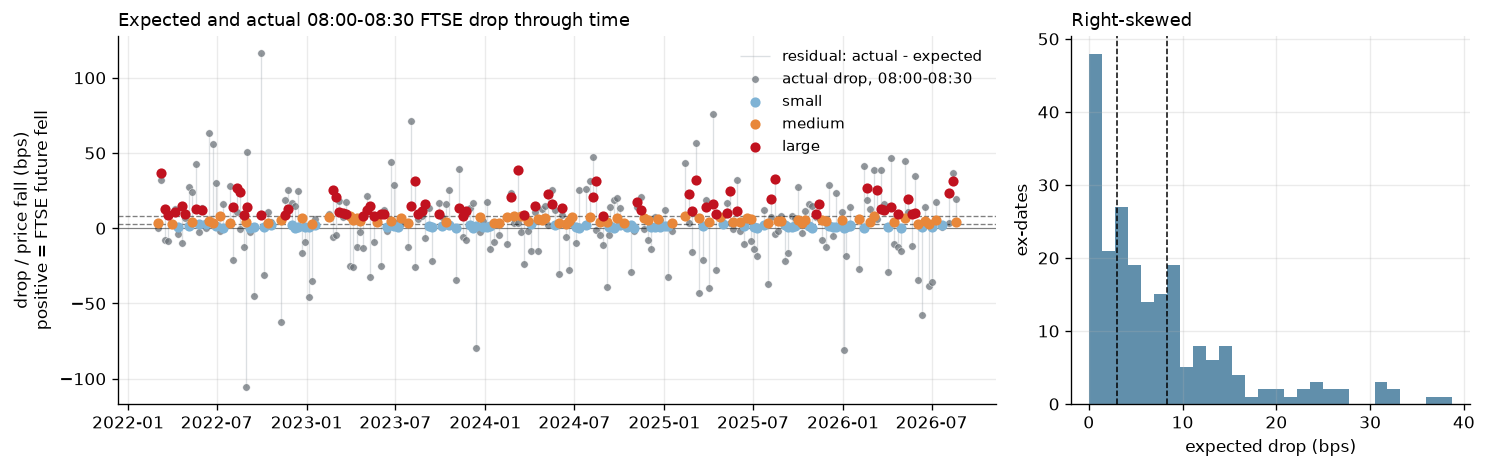

In [34]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.0),
                             gridspec_kw={"width_ratios": [2.2, 1]})

# Match the regression convention: positive means the FTSE future fell from
# 08:00 to 08:30.  The vertical segment is actual minus expected for that date.
actual_drop_0830 = -(mid[OPEN_M + 30] - mid[OPEN_M]) / mid[OPEN_M] * 1e4
plot_days = days[days["drop_T"] > 0].copy()
plot_days["actual_drop_0830"] = actual_drop_0830.reindex(plot_days.index)
plot_days = plot_days.dropna(subset=["actual_drop_0830"])

a1.vlines(plot_days.index, plot_days["drop_T"], plot_days["actual_drop_0830"],
          color="#9aa5ad", alpha=0.35, lw=0.8, zorder=1,
          label="residual: actual - expected")
a1.scatter(plot_days.index, plot_days["actual_drop_0830"], s=20,
           color="#6b7278", alpha=0.75, edgecolor="white", linewidth=0.35,
           label="actual drop, 08:00-08:30", zorder=2)
for g in GROUP_ORDER[1:]:
    s = plot_days[plot_days["group_T"] == g]
    a1.scatter(s.index, s["drop_T"], s=26, color=GCOL[g], label=g, zorder=3)
a1.axhline(0, color="k", lw=0.7, alpha=0.45)
for c in cuts:
    a1.axhline(c, color="k", lw=0.8, ls="--", alpha=0.5)
a1.set_ylabel("drop / price fall (bps)\npositive = FTSE future fell")
a1.set_title("Expected and actual 08:00-08:30 FTSE drop through time", loc="left",
             fontsize=10.5)
a1.legend(frameon=False, fontsize=9)
a2.hist(exdiv["drop_bps"], bins=28, color="#457b9d", alpha=0.85)
for c in cuts:
    a2.axvline(c, color="k", lw=0.9, ls="--")
a2.set_xlabel("expected drop (bps)")
a2.set_ylabel("ex-dates")
a2.set_title("Right-skewed", loc="left", fontsize=10.5)
fig.tight_layout()
plt.show()

## 4. Measures

Two families. Every measure is a change in bps between two minutes; the T−1→T hold
crosses sessions and uses price levels directly.

**Morning of T** (labelled `group_T` / `drop_T`)

| name | window |
|---|---|
| `T_overnight` | 01:00 → 07:59 |
| `T_gap` | 07:59 → 08:00, the uncrossing |
| `T_open5` / `T_open30` / `T_open60` | 07:59 → 08:05 / 08:30 / 09:00 |

**Close of T−1** (labelled `group_T1` / `drop_T1`)

| name | window |
|---|---|
| `T1_aft` | 15:00 → 16:30 |
| `T1_close30` | 16:00 → 16:30 |
| `T1_last10` | 16:20 → 16:30 |
| `T1_auction` | 16:30 → 16:40 |

**Across the two** (labelled by T's drop — it is the same event)

| name | window |
|---|---|
| `hold_1600_to_0830` | T−1 16:00 → T 08:30 |
| `hold_1630_to_0800` | T−1 16:30 → T 08:00, i.e. pure overnight |

In [35]:
T_WINDOWS = {"T_overnight": (0, ANCHOR_M), "T_gap": (ANCHOR_M, OPEN_M),
             "T_open5": (ANCHOR_M, OPEN_M + 5),
             "T_open30": (ANCHOR_M, OPEN_M + 30),
             "T_open60": (ANCHOR_M, OPEN_M + 60)}
T1_WINDOWS = {"T1_aft": (840, CLOSE_M), "T1_close30": (900, CLOSE_M),
              "T1_last10": (920, CLOSE_M), "T1_auction": (CLOSE_M, 940)}

react = pd.DataFrame(index=mid.index)
for k, (a, b) in {**T_WINDOWS, **T1_WINDOWS}.items():
    react[k] = (mid[b] - mid[a]) / mid[a] * 1e4

# cross-session holds: value on T versus a level on the PREVIOUS trading day
prev_mid_1600 = mid[900].reindex(days["prev_date"]).to_numpy()
prev_mid_1630 = mid[CLOSE_M].reindex(days["prev_date"]).to_numpy()
react["hold_1600_to_0830"] = (mid[OPEN_M + 30].to_numpy() - prev_mid_1600) \
    / prev_mid_1600 * 1e4
react["hold_1630_to_0800"] = (mid[OPEN_M].to_numpy() - prev_mid_1630) \
    / prev_mid_1630 * 1e4

HOLD = ["hold_1600_to_0830", "hold_1630_to_0800"]
react = react.join(days[["drop_T", "drop_T1", "group_T", "group_T1", "weekday"]])
react["vol_T1_close30"] = vol.loc[:, 900:CLOSE_M].sum(axis=1)
react["vol_T_open30"] = vol.loc[:, OPEN_M:OPEN_M + 30].sum(axis=1)
print(f"{len(react)} days x {len(T_WINDOWS) + len(T1_WINDOWS) + len(HOLD)} measures")
react[list(T_WINDOWS) + list(T1_WINDOWS) + HOLD].describe().round(2)

1127 days x 11 measures


,T_overnight,T_gap,T_open5,T_open30,T_open60,T1_aft,T1_close30,T1_last10,T1_auction,hold_1600_to_0830,hold_1630_to_0800
count,1127.00,1127.00,1127.00,1127.00,1127.00,1127.00,1127.00,1127.00,1127.00,1126.00,1126.00
mean,1.72,-1.09,-0.28,-1.30,-0.60,-1.23,-0.83,-1.04,0.39,2.05,3.02
std,68.48,61.96,60.09,57.01,53.81,26.65,14.94,9.00,10.70,60.59,52.08
min,-474.17,-226.10,-278.76,-261.86,-258.99,-130.66,-193.28,-91.84,-53.32,-536.82,-461.12
25%,-33.66,-34.43,-33.93,-31.61,-30.09,-14.81,-8.14,-5.04,-5.15,-27.25,-22.75
50%,3.77,-3.53,-2.69,-4.00,-2.58,0.00,0.00,-0.26,0.00,4.32,4.72
75%,37.48,29.43,30.69,29.13,27.82,14.81,7.53,4.12,5.87,34.80,30.08
max,272.69,443.84,446.32,427.72,388.05,95.67,67.89,45.19,103.57,549.12,588.71


## 5. Dose-response — the test

`lambda = -slope` from regressing each move on the expected drop. Morning measures
use T's drop; close measures use the **next** day's drop. Each is run on flagged days
only (clean: all the same weekday) and on all days with zero elsewhere.

Signs to expect: on the **T−1 close**, cum-dividend demand predicts `lambda < 0`
(futures strength ahead of a big dividend). On the **T morning**, the future
following the index down predicts `0 < lambda <= 1`.

In [36]:
def dose(y, x, mask, label):
    d = pd.DataFrame({"y": y, "x": x})[mask].dropna()
    r = stats.linregress(d["x"], d["y"])
    return {"measure": label, "n": len(d), "lambda": -r.slope,
            "se": r.stderr, "t": r.slope / r.stderr, "p": r.pvalue,
            "lam_lo": -(r.slope + 1.96 * r.stderr),
            "lam_hi": -(r.slope - 1.96 * r.stderr)}


rows = []
for k in T_WINDOWS:
    rows.append(dose(react[k], react["drop_T"], react["drop_T"] > 0, k))
for k in T1_WINDOWS:
    rows.append(dose(react[k], react["drop_T1"], react["drop_T1"] > 0, k))
for k in HOLD:
    rows.append(dose(react[k], react["drop_T"], react["drop_T"] > 0, k))
print("FLAGGED DAYS ONLY (no weekday confound)")
print(pd.DataFrame(rows).set_index("measure").round(
    {"lambda": 3, "se": 3, "t": 2, "p": 3, "lam_lo": 3, "lam_hi": 3}).to_string())

rows = []
for k in T_WINDOWS:
    rows.append(dose(react[k], react["drop_T"], react["drop_T"].notna(), k))
for k in T1_WINDOWS:
    rows.append(dose(react[k], react["drop_T1"].fillna(0),
                     react["drop_T1"].notna(), k))
for k in HOLD:
    rows.append(dose(react[k], react["drop_T"], react[k].notna(), k))
print("\nALL DAYS (drop = 0 when none)")
print(pd.DataFrame(rows).set_index("measure").round(
    {"lambda": 3, "se": 3, "t": 2, "p": 3, "lam_lo": 3, "lam_hi": 3}).to_string())
print("\nlambda = 0 -> no relationship. On the morning side lambda > 1 is")
print("IMPOSSIBLE as a dividend story: a dividend can only be given up once.")

FLAGGED DAYS ONLY (no weekday confound)
                     n  lambda     se     t      p  lam_lo  lam_hi
measure                                                           
T_overnight        216   0.952  0.653 -1.46  0.146  -0.328   2.233
T_gap              216  -1.054  0.596  1.77  0.079  -2.223   0.115
T_open5            216  -0.912  0.589  1.55  0.123  -2.067   0.243
T_open30           216  -0.281  0.527  0.53  0.594  -1.314   0.751
T_open60           216  -0.087  0.488  0.18  0.859  -1.043   0.869
T1_aft             215   0.128  0.216 -0.60  0.552  -0.294   0.551
T1_close30         215  -0.055  0.123  0.45  0.655  -0.295   0.186
T1_last10          215  -0.207  0.068  3.07  0.002  -0.340  -0.075
T1_auction         215  -0.300  0.104  2.89  0.004  -0.503  -0.096
hold_1600_to_0830  215  -0.044  0.595  0.07  0.941  -1.210   1.122
hold_1630_to_0800  215  -0.762  0.546  1.40  0.164  -1.833   0.308

ALL DAYS (drop = 0 when none)
                      n  lambda     se     t      p  lam_l

In [37]:
def group_stats(measure, gcol):
    rows = []
    for g in GROUP_ORDER:
        v = react.loc[react[gcol] == g, measure].dropna()
        se = v.std(ddof=1) / np.sqrt(len(v)) if len(v) > 1 else np.nan
        rows.append({"group": g, "n": len(v), "mean_bps": v.mean(),
                     "median": v.median(), "sd": v.std(ddof=1),
                     "t_vs_0": v.mean() / se if se else np.nan})
    out = pd.DataFrame(rows).set_index("group")
    lv = react.loc[react[gcol] == "large", measure].dropna()
    sv = react.loc[react[gcol] == "small", measure].dropna()
    nv = react.loc[react[gcol] == "none", measure].dropna()
    return (out, stats.ttest_ind(lv, sv, equal_var=False),
            stats.ttest_ind(lv, nv, equal_var=False))


for title, keys, gcol in [("CLOSE OF T-1", list(T1_WINDOWS), "group_T1"),
                          ("MORNING OF T", list(T_WINDOWS), "group_T"),
                          ("ACROSS BOTH", HOLD, "group_T")]:
    print(f"\n{'=' * 66}\n{title}  (grouped by {gcol})\n{'=' * 66}")
    for k in keys:
        t, ls, ln = group_stats(k, gcol)
        print(f"\n--- {k} ---")
        print(t.round(3).to_string())
        print(f"  large vs small: "
              f"{t.loc['large', 'mean_bps'] - t.loc['small', 'mean_bps']:+.2f} bps, "
              f"t={ls.statistic:+.2f}, p={ls.pvalue:.3f}  [confound-free]")
        print(f"  large vs none : "
              f"{t.loc['large', 'mean_bps'] - t.loc['none', 'mean_bps']:+.2f} bps, "
              f"t={ln.statistic:+.2f}, p={ln.pvalue:.3f}  [weekday-confounded]")


CLOSE OF T-1  (grouped by group_T1)

--- T1_aft ---
          n  mean_bps  median      sd  t_vs_0
group                                        
none    912    -1.160   0.309  27.166  -1.290
small    72    -2.207   0.000  21.847  -0.857
medium   71     1.512   1.705  22.980   0.554
large    72    -3.821  -2.450  27.975  -1.159
  large vs small: -1.61 bps, t=-0.39, p=0.700  [confound-free]
  large vs none : -2.66 bps, t=-0.78, p=0.438  [weekday-confounded]

--- T1_close30 ---
          n  mean_bps  median      sd  t_vs_0
group                                        
none    912    -1.122   0.000  15.170  -2.234
small    72    -0.227   0.000  13.756  -0.140
medium   71     0.012   1.758  11.911   0.008
large    72     1.511   1.555  15.793   0.812
  large vs small: +1.74 bps, t=+0.70, p=0.483  [confound-free]
  large vs none : +2.63 bps, t=+1.37, p=0.176  [weekday-confounded]

--- T1_last10 ---
          n  mean_bps  median     sd  t_vs_0
group                                       
none

## 5b. Expected drop vs actual drop — parameter-selected trade window

The direct scatter. **Sign convention: both axes are DROPS**, so a positive actual
value means the future *fell*. That makes the fitted slope read straight off as
`lambda`, with no sign flip.

Two reference lines carry the whole interpretation:

- **`y = 0`** — theory. The future already embeds the dividend, so it should not move.
- **`y = x`** — `lambda = 1`, the future giving up exactly the full dividend. This is
  the **ceiling** on any dividend explanation: a dividend can only be given up once.

The window starts at 08:00 and ends at the user-selected `TRADE_EXIT_TIME`. It
excludes the uncrossing gap and therefore sits on real two-sided quotes rather
than the one-sided pre-open book.

In [38]:
# both axes as DROPS: positive = the future fell
sc = pd.DataFrame({
    "expected": days["drop_T"],
    "actual": -(mid[TRADE_EXIT_M] - mid[OPEN_M]) / mid[OPEN_M] * 1e4,
    "actual_from_0759": -(mid[TRADE_EXIT_M] - mid[ANCHOR_M]) / mid[ANCHOR_M] * 1e4,
    "group": days["group_T"],
}).loc[days["drop_T"] > 0].dropna(subset=["expected", "actual"])

fit = stats.linregress(sc["expected"], sc["actual"])
pear = stats.pearsonr(sc["expected"], sc["actual"])
spear = stats.spearmanr(sc["expected"], sc["actual"])
kend = stats.kendalltau(sc["expected"], sc["actual"])
print(f"n = {len(sc)} ex-dividend dates\n")
print(f"Pearson  r   = {pear[0]:+.3f}   p = {pear[1]:.4f}")
print(f"Spearman rho = {spear[0]:+.3f}   p = {spear[1]:.4f}")
print(f"Kendall  tau = {kend[0]:+.3f}   p = {kend[1]:.4f}")
print(f"\nslope (lambda) = {fit.slope:+.3f} +/- {fit.stderr:.3f}   "
      f"t = {fit.slope / fit.stderr:+.2f}   p = {fit.pvalue:.4f}")
x_intercept = (-fit.intercept / fit.slope
               if not np.isclose(fit.slope, 0.0) else np.nan)
print(f"y-intercept (expected = 0) = {fit.intercept:+.2f} bps")
print(f"x-intercept (actual = 0)   = {x_intercept:+.2f} bps")
print(f"R^2 = {fit.rvalue ** 2:.3f}")
print(f"95% CI on lambda: [{fit.slope - 1.96 * fit.stderr:+.2f}, "
      f"{fit.slope + 1.96 * fit.stderr:+.2f}]  "
      f"-> {'EXCLUDES' if fit.slope - 1.96 * fit.stderr > 1 else 'includes'} "
      f"lambda = 1")

nonex = (-(mid[TRADE_EXIT_M] - mid[OPEN_M]) / mid[OPEN_M] * 1e4)[days["drop_T"] == 0]
print(f"\nreference: on non-ex-div days the same 08:00-{TRADE_EXIT_TIME} move averages "
      f"{nonex.mean():+.2f} bps (sd {nonex.std():.1f})")
print(f"R^2 = {fit.rvalue ** 2:.3f} means expected drop explains only "
      f"{fit.rvalue ** 2 * 100:.0f}% of the variance -- expect a cloud, not a line.")

n = 216 ex-dividend dates

Pearson  r   = +0.235   p = 0.0005
Spearman rho = +0.285   p = 0.0000
Kendall  tau = +0.192   p = 0.0000

slope (lambda) = +1.176 +/- 0.332   t = +3.54   p = 0.0005
y-intercept (expected = 0) = -3.26 bps
x-intercept (actual = 0)   = +2.77 bps
R^2 = 0.055
95% CI on lambda: [+0.52, +1.83]  -> includes lambda = 1

reference: on non-ex-div days the same 08:00-10:00 move averages -1.21 bps (sd 37.1)
R^2 = 0.055 means expected drop explains only 6% of the variance -- expect a cloud, not a line.


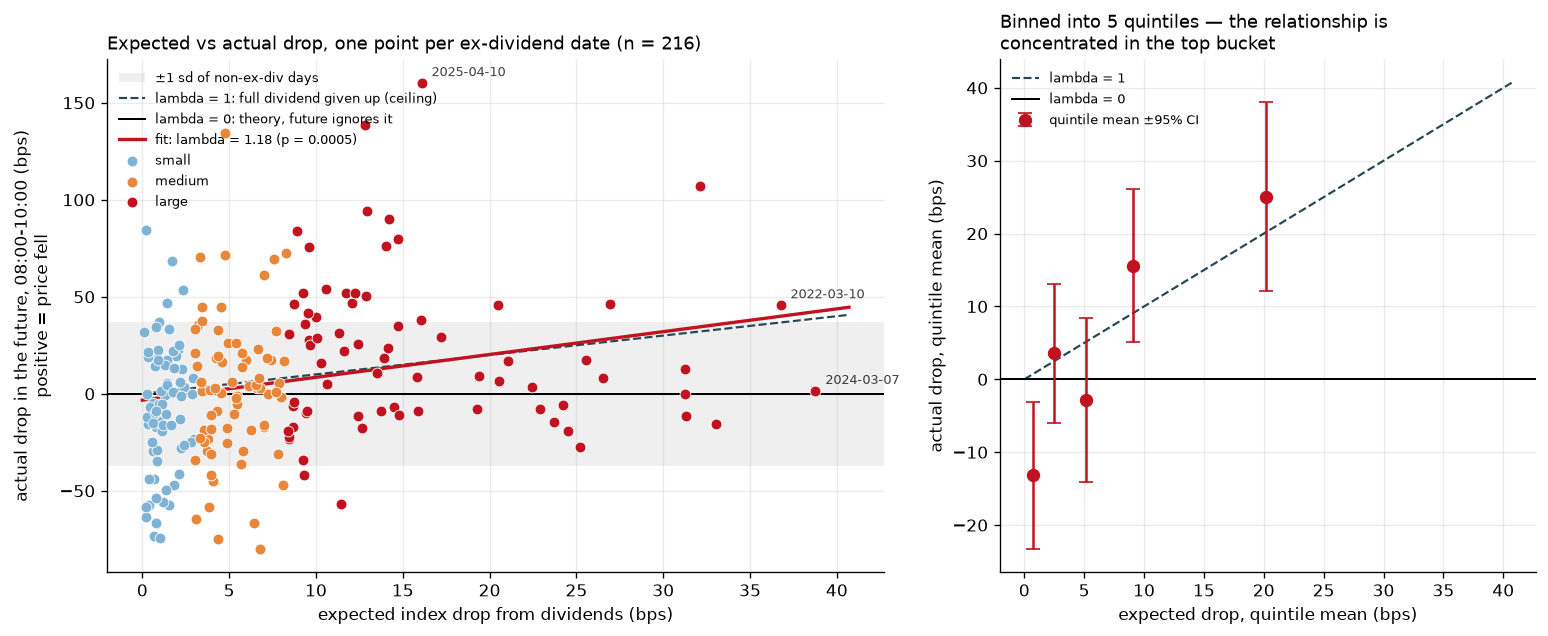

Quintiles of expected drop:
        n  exp_mean  act_mean  act_sd  pct_fell    se  t_vs_0
quint                                                        
0      44      0.73    -13.17   34.09      30.0  5.14   -2.56
1      43      2.48      3.57   31.80      60.0  4.85    0.74
2      43      5.16     -2.82   37.60      51.0  5.73   -0.49
3      43      9.04     15.56   35.13      63.0  5.36    2.90
4      43     20.21     25.04   43.34      65.0  6.61    3.79


In [39]:
QN = 5
sc["quint"] = pd.qcut(sc["expected"], QN, labels=False)
qt = sc.groupby("quint").agg(
    n=("expected", "size"), exp_mean=("expected", "mean"),
    act_mean=("actual", "mean"), act_sd=("actual", "std"),
    pct_fell=("actual", lambda s: (s > 0).mean() * 100))
qt["se"] = qt["act_sd"] / np.sqrt(qt["n"])
qt["t_vs_0"] = qt["act_mean"] / qt["se"]

fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.4),
                         gridspec_kw={"width_ratios": [1.45, 1]})

ax = axes[0]
xs = np.linspace(0, sc["expected"].max() * 1.05, 100)
ax.axhspan(-nonex.std(), nonex.std(), color="#b0b0b0", alpha=0.20, lw=0, zorder=0,
           label="±1 sd of non-ex-div days")
ax.plot(xs, xs, color="#264653", lw=1.3, ls="--",
        label="lambda = 1: full dividend given up (ceiling)")
ax.axhline(0, color="k", lw=1.2, label="lambda = 0: theory, future ignores it")
ax.plot(xs, fit.intercept + fit.slope * xs, color="#c1121f", lw=2.0,
        label=f"fit: lambda = {fit.slope:.2f} (p = {fit.pvalue:.4f})")
for g in GROUP_ORDER[1:]:
    s = sc[sc["group"] == g]
    ax.scatter(s["expected"], s["actual"], s=42, color=GCOL[g],
               edgecolor="white", linewidth=0.5, zorder=3, label=g)
for lbl in sc.nlargest(2, "expected").index.union(sc.nlargest(1, "actual").index):
    ax.annotate(lbl.strftime("%Y-%m-%d"),
                xy=(sc.loc[lbl, "expected"], sc.loc[lbl, "actual"]),
                xytext=(6, 4), textcoords="offset points", fontsize=7.5,
                alpha=0.75)
ax.set_xlabel("expected index drop from dividends (bps)")
ax.set_ylabel(f"actual drop in the future, 08:00-{TRADE_EXIT_TIME} (bps)\n"
              "positive = price fell")
ax.set_title(f"Expected vs actual drop, one point per ex-dividend date "
             f"(n = {len(sc)})", loc="left", fontsize=10.5)
ax.legend(frameon=False, fontsize=7.8, loc="upper left")

ax = axes[1]
ax.errorbar(qt["exp_mean"], qt["act_mean"], yerr=1.96 * qt["se"], fmt="o",
            ms=7, capsize=4, color="#c1121f", zorder=3, label="quintile mean ±95% CI")
ax.plot(xs, xs, color="#264653", lw=1.3, ls="--", label="lambda = 1")
ax.axhline(0, color="k", lw=1.2, label="lambda = 0")
ax.set_xlabel("expected drop, quintile mean (bps)")
ax.set_ylabel("actual drop, quintile mean (bps)")
ax.set_title(f"Binned into {QN} quintiles — the relationship is\nconcentrated in the "
             f"top bucket", loc="left", fontsize=10.5)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

print("Quintiles of expected drop:")
print(qt.round({"exp_mean": 2, "act_mean": 2, "act_sd": 2, "se": 2,
                "t_vs_0": 2, "pct_fell": 0}).to_string())

### Is the correlation real, or one or two days?

`R^2 = 0.13` means the scatter is mostly cloud, and a handful of extreme days could
in principle carry the whole fit. Every leave-out and rank-based check below.

In [40]:
def check(frame, label):
    r = stats.linregress(frame["expected"], frame["actual"])
    pr = stats.pearsonr(frame["expected"], frame["actual"])
    sp = stats.spearmanr(frame["expected"], frame["actual"])
    print(f"  {label:34s} n={len(frame):3d}  lambda={r.slope:+6.3f}  "
          f"p={r.pvalue:6.4f}  R2={r.rvalue ** 2:.3f}  r={pr[0]:+.3f}  "
          f"rho={sp[0]:+.3f} (p={sp[1]:.3f})")


check(sc, "all ex-dividend dates")
check(sc.drop(sc["actual"].idxmax()), "excl. largest ACTUAL drop")
check(sc.drop(sc.nlargest(1, "expected").index), "excl. largest EXPECTED")
check(sc.drop(sc.nlargest(5, "expected").index), "excl. 5 largest EXPECTED")
check(sc.drop(sc.nlargest(3, "actual").index), "excl. 3 largest ACTUAL")
w = sc.copy()
w["actual"] = w["actual"].clip(*np.percentile(w["actual"], [5, 95]))
check(w, "actual winsorised at 5/95")

top = sc[sc["quint"] == QN - 1]
print(f"\nTop quintile only (n={len(top)}, mean expected "
      f"{top['expected'].mean():.1f} bps):")
print(f"  mean actual drop      {top['actual'].mean():+.2f} bps  "
      f"(t vs 0 = {top['actual'].mean() / (top['actual'].std(ddof=1) / np.sqrt(len(top))):+.2f})")
t2 = top.drop(top["actual"].idxmax())
print(f"  excl. its largest     {t2['actual'].mean():+.2f} bps  "
      f"(t vs 0 = {t2['actual'].mean() / (t2['actual'].std(ddof=1) / np.sqrt(len(t2))):+.2f})")
print(f"  median                {top['actual'].median():+.2f} bps")
print(f"  Wilcoxon vs 0         p = {stats.wilcoxon(top['actual']).pvalue:.4f}")
print(f"  share that FELL       {(top['actual'] > 0).mean() * 100:.0f}%  "
      f"({int((top['actual'] > 0).sum())} of {len(top)})")
print(f"\n  vs bottom quintile:   {sc[sc['quint'] == 0]['actual'].mean():+.2f} bps, "
      f"{(sc[sc['quint'] == 0]['actual'] > 0).mean() * 100:.0f}% fell")

  all ex-dividend dates              n=216  lambda=+1.176  p=0.0005  R2=0.055  r=+0.235  rho=+0.285 (p=0.000)
  excl. largest ACTUAL drop          n=215  lambda=+1.078  p=0.0010  R2=0.050  r=+0.223  rho=+0.278 (p=0.000)
  excl. largest EXPECTED             n=215  lambda=+1.284  p=0.0003  R2=0.061  r=+0.247  rho=+0.288 (p=0.000)
  excl. 5 largest EXPECTED           n=211  lambda=+1.367  p=0.0006  R2=0.055  r=+0.235  rho=+0.286 (p=0.000)
  excl. 3 largest ACTUAL             n=213  lambda=+1.052  p=0.0007  R2=0.054  r=+0.232  rho=+0.274 (p=0.000)
  actual winsorised at 5/95          n=216  lambda=+0.987  p=0.0008  R2=0.051  r=+0.226  rho=+0.286 (p=0.000)

Top quintile only (n=43, mean expected 20.2 bps):
  mean actual drop      +25.04 bps  (t vs 0 = +3.79)
  excl. its largest     +21.82 bps  (t vs 0 = +3.69)
  median                +10.78 bps
  Wilcoxon vs 0         p = 0.0012
  share that FELL       65%  (28 of 43)

  vs bottom quintile:   -13.17 bps, 30% fell


### Is the sample big enough?

Expected drops are small — the mean ex-dividend day is only a few bps. Against
day-to-day noise that sets a floor on what any test can resolve, so this prints the
minimum detectable `lambda`. Where that floor is above 1, a null result carries no
information: even a *full* dividend response would be invisible.

In [41]:
Z = stats.norm.ppf(0.975) + stats.norm.ppf(0.80)
print(f"{'measure':20s} {'group':9s} {'sd(bps)':>8s} {'drop gap':>9s} "
      f"{'min lambda':>11s}")
for keys, gcol in [(list(T1_WINDOWS), "group_T1"), (list(T_WINDOWS), "group_T"),
                   (HOLD, "group_T")]:
    dcol = "drop_T1" if gcol == "group_T1" else "drop_T"
    gap = (react.loc[react[gcol] == "large", dcol].mean()
           - react.loc[react[gcol] == "small", dcol].mean())
    for k in keys:
        lv = react.loc[react[gcol] == "large", k].dropna()
        sv = react.loc[react[gcol] == "small", k].dropna()
        sd = np.sqrt((lv.var(ddof=1) + sv.var(ddof=1)) / 2)
        mde = Z * sd * np.sqrt(1 / len(lv) + 1 / len(sv))
        flag = "  <- underpowered" if mde / gap > 1 else ""
        print(f"{k:20s} {gcol:9s} {sd:8.2f} {gap:9.2f} {mde / gap:11.2f}{flag}")

measure              group      sd(bps)  drop gap  min lambda
T1_aft               group_T1     25.10     14.74        0.80
T1_close30           group_T1     14.81     14.74        0.47
T1_last10            group_T1      7.96     14.74        0.25
T1_auction           group_T1     13.02     14.74        0.41
T_overnight          group_T      73.44     14.74        2.33  <- underpowered
T_gap                group_T      65.94     14.74        2.09  <- underpowered
T_open5              group_T      65.50     14.74        2.08  <- underpowered
T_open30             group_T      58.81     14.74        1.86  <- underpowered
T_open60             group_T      54.52     14.74        1.73  <- underpowered
hold_1600_to_0830    group_T      73.37     14.74        2.32  <- underpowered
hold_1630_to_0800    group_T      68.28     14.74        2.16  <- underpowered


## 6. The charts — the two windows side by side

Left: the run-in to the close on T−1. Right: the ex-dividend morning. Both coloured
by the **same** event's dividend size, so a single line colour can be followed
across the two panels.

Each panel is rebased inside itself (T−1 at 15:00, T at 07:59) because they sit on
different days; the overnight gap between them is measured separately by
`hold_1630_to_0800` rather than being drawn as if it were continuous.

**Shaded bands are 95% confidence intervals** on each group mean (t-based, so the
33-day buckets are not flattered by a normal approximation). The contrast in band
width is itself informative: `none` has 407 days and a band a few tenths of a bp
wide, while each size bucket has 33 and a band of roughly ±8 bps. Where the bucket
bands overlap each other, the groups are not distinguishable at that minute however
far apart the lines look. Set `show_ci=False` to switch them off, or
`ci_groups=["large", "none"]` to band only the two that matter.

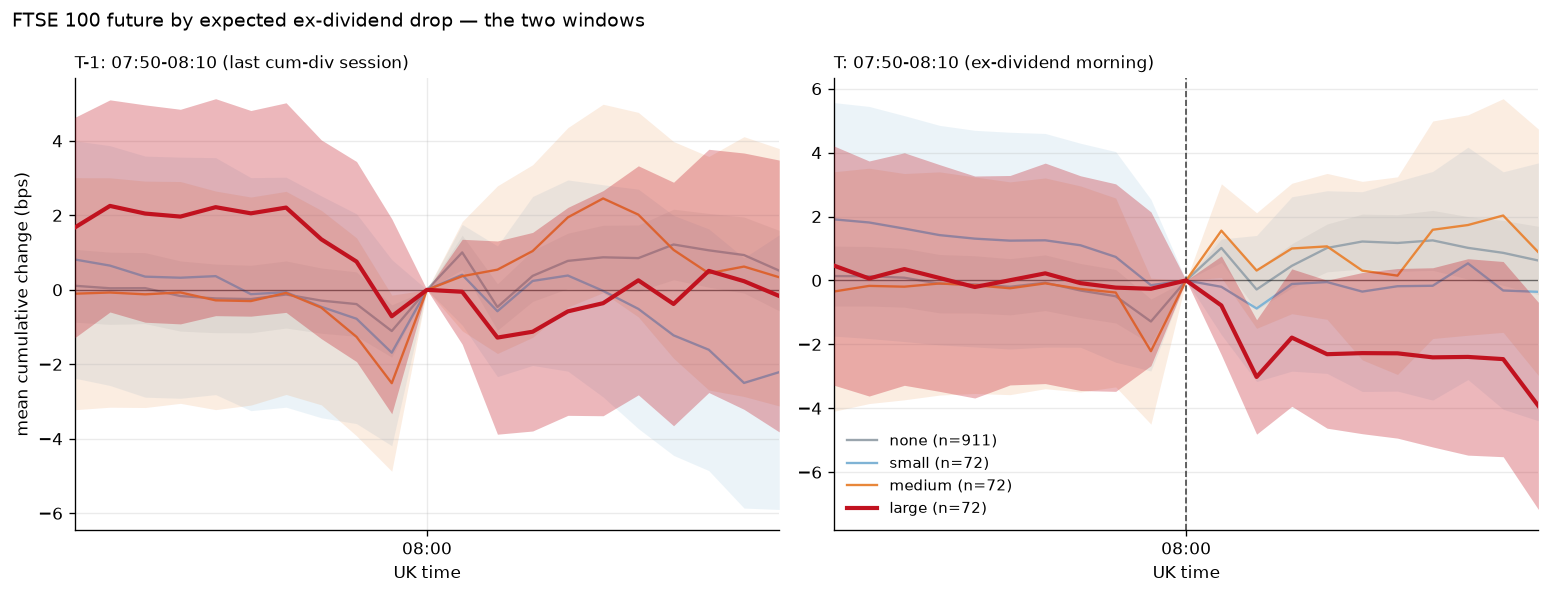

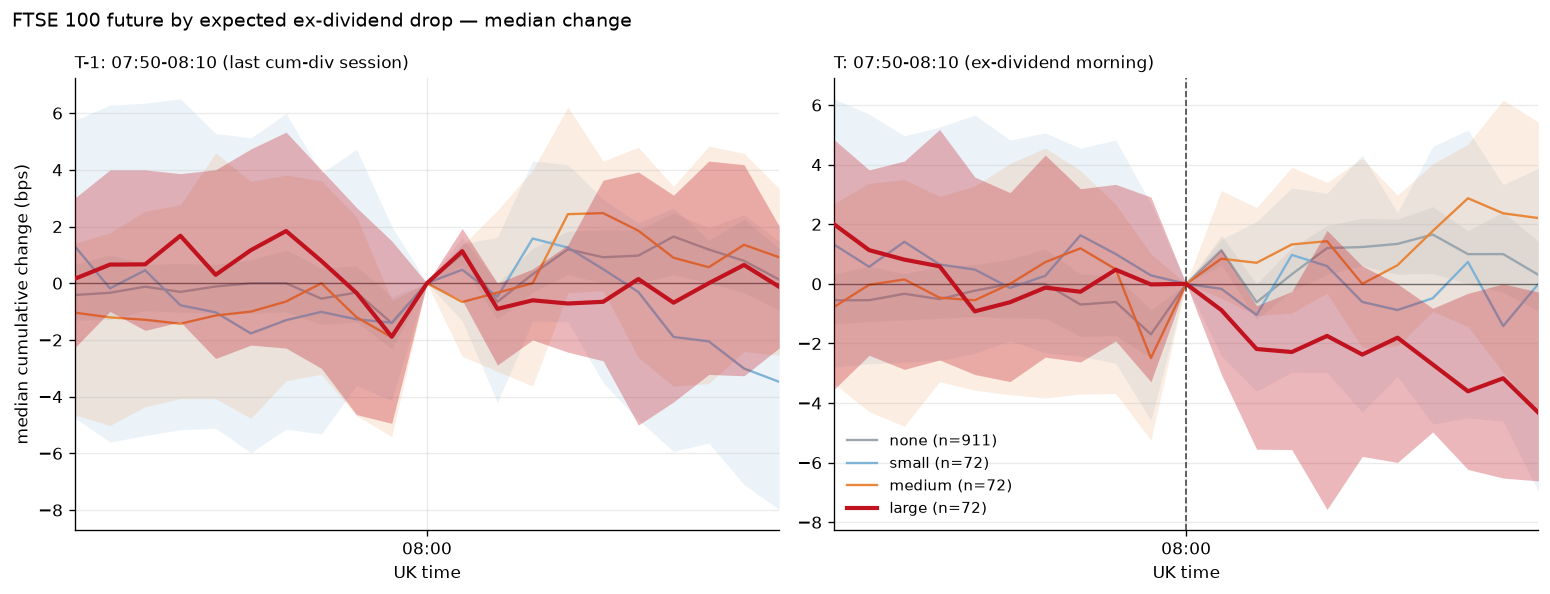

In [48]:
def two_panel(t1_from, t1_to, t_from, t_to, fname, value="mid", ylab=None,
              title="", smooth=1, show_ci=True, ci_groups=None,
              statistic="mean", left_base=CLOSE_M):
    # Left = T-1 window (group_T1), right = T window (group_T). Same events.
    # Mean bands use a t interval. Median bands use an exact, distribution-free
    # order-statistic interval. ci_groups restricts which buckets get a band.
    # left_base = minute the T-1 panel is rebased to (CLOSE_M 16:30, OPEN_M 08:00).
    l0, l1 = uk_to_m(t1_from), uk_to_m(t1_to)
    r0, r1 = uk_to_m(t_from), uk_to_m(t_to)
    band_for = set(ci_groups if ci_groups is not None else GROUP_ORDER)
    src = panel.pivot_table(index="date", columns="m", values=value)
    fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.0),
                             gridspec_kw={"width_ratios":
                                          [(l1 - l0) or 1, (r1 - r0) or 1]})
    for ax, (a, b, gcol, base, ttl) in zip(axes, [
            (l0, l1, "group_T1", 420, f"T-1: {t1_from}-{t1_to} (last cum-div session)"),
            (r0, r1, "group_T", 420, f"T: {t_from}-{t_to} (ex-dividend morning)")]):
        for g in GROUP_ORDER:
            idx = days.index[days[gcol] == g]
            seg = src.loc[idx, a:b]
            if value == "mid":
                seg = (seg.div(src.loc[idx, base], axis=0) - 1.0) * 1e4
            if statistic == "mean":
                s = seg.mean(axis=0)
                n = seg.count(axis=0)
                half = (stats.t.ppf(0.975, np.maximum(n - 1, 1))
                        * seg.std(axis=0, ddof=1) / np.sqrt(n.clip(lower=1)))
                lower, upper = s - half, s + half
            elif statistic == "median":
                s = seg.median(axis=0)
                lower, upper = [], []
                for col in seg.columns:
                    vals = np.sort(seg[col].dropna().to_numpy())
                    n = len(vals)
                    if n == 0:
                        lower.append(np.nan)
                        upper.append(np.nan)
                        continue
                    k = int(stats.binom.ppf(0.025, n, 0.5))
                    lower.append(vals[max(k - 1, 0)])
                    upper.append(vals[min(n - k, n - 1)])
                lower = pd.Series(lower, index=seg.columns)
                upper = pd.Series(upper, index=seg.columns)
            else:
                raise ValueError("statistic must be 'mean' or 'median'")
            if smooth > 1:
                s = s.rolling(smooth, center=True, min_periods=1).mean()
                lower = lower.rolling(smooth, center=True, min_periods=1).mean()
                upper = upper.rolling(smooth, center=True, min_periods=1).mean()
            if show_ci and g in band_for:
                ax.fill_between(s.index, lower.to_numpy(), upper.to_numpy(),
                                color=GCOL[g],
                                alpha=0.30 if g == "large" else 0.15, lw=0,
                                zorder=3 if g == "large" else 1)
            ax.plot(s.index, s.to_numpy(), color=GCOL[g],
                    lw=2.5 if g == "large" else 1.4,
                    zorder=4 if g == "large" else 2, label=f"{g} (n={len(idx)})")
        ax.axhline(0, color="k", lw=0.8, alpha=0.5)
        ticks = [m for m in range(a, b + 1) if (60 + m) % 30 == 0]
        ax.set_xticks(ticks)
        ax.set_xticklabels([m_to_uk(m) for m in ticks])
        ax.set_xlim(a, b)
        ax.set_title(ttl, loc="left", fontsize=10)
        ax.set_xlabel("UK time")
    axes[0].set_ylabel(ylab or f"{statistic} cumulative change (bps)")
    axes[0].axvline(CLOSE_M, color="#e76f51", lw=1.0, ls="--", alpha=0.7)
    axes[1].axvline(OPEN_M, color="k", lw=1.0, ls="--", alpha=0.7)
    axes[1].legend(frameon=False, fontsize=9)
    fig.suptitle(title, x=0.01, ha="left", fontsize=11.5)
    fig.tight_layout()
    plt.show()


two_panel("07:50", "08:10", "07:50", "08:10", "chart_two_windows_price.png",
          title="FTSE 100 future by expected ex-dividend drop — the two windows",
          show_ci=True, left_base=OPEN_M)

two_panel("07:50", "08:10", "07:50", "08:10", "chart_two_windows_price_median.png",
          title="FTSE 100 future by expected ex-dividend drop — median change",
          show_ci=True, statistic="median", left_base=OPEN_M)

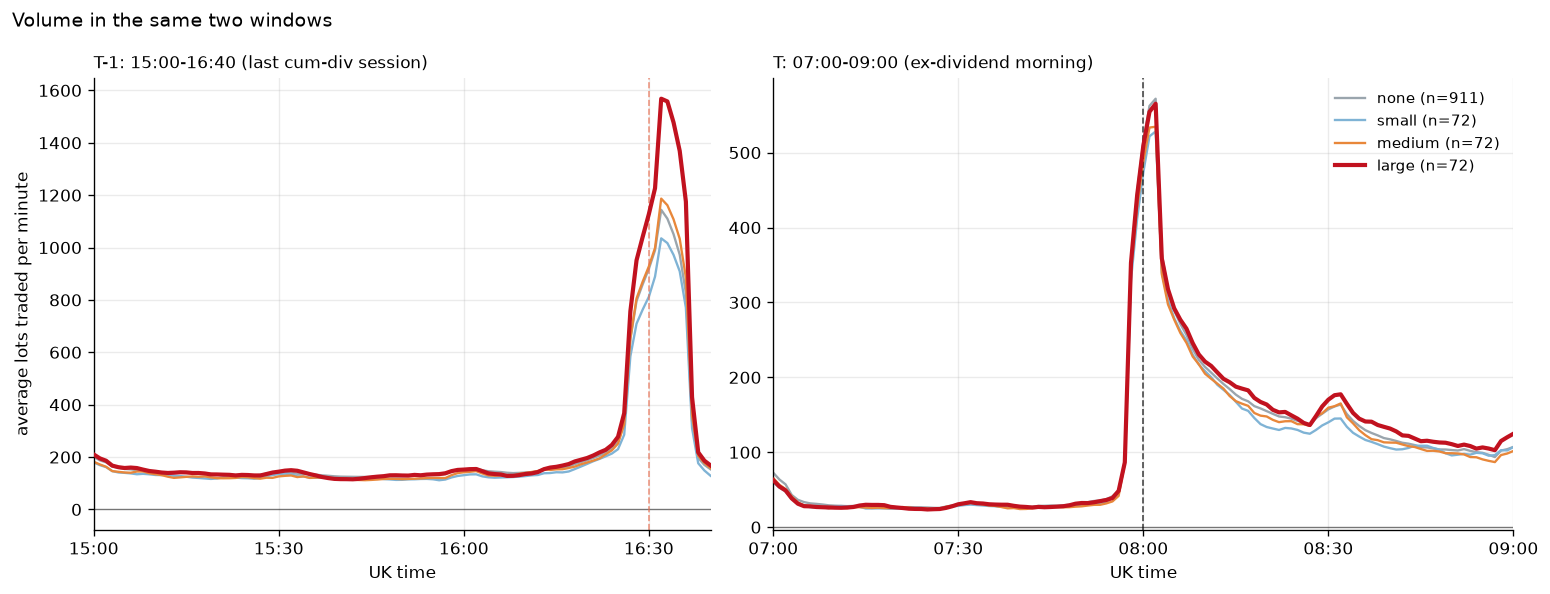

Volume by group (lots):
        T-1 16:00-16:30  T 08:00-08:30
none             8325.0         7604.0
small            7437.0         7069.0
medium           8186.0         7274.0
large            9140.0         7764.0
  T-1 close30: volume vs expected drop  slope +36 lots/bp, t=+1.63, p=0.103
  T open30: volume vs expected drop  slope -5 lots/bp, t=-0.23, p=0.818


In [43]:
two_panel("15:00", "16:40", "07:00", "09:00", "chart_two_windows_volume.png",
          value="vol", ylab="average lots traded per minute",
          title="Volume in the same two windows", smooth=5, show_ci=False)

print("Volume by group (lots):")
print(pd.DataFrame({
    "T-1 16:00-16:30": react.groupby("group_T1", observed=True)["vol_T1_close30"]
                            .mean(),
    "T 08:00-08:30": react.groupby("group_T", observed=True)["vol_T_open30"].mean(),
}).reindex(GROUP_ORDER).round(0).to_string())
for lbl, vcol, dcol in [("T-1 close30", "vol_T1_close30", "drop_T1"),
                        ("T open30", "vol_T_open30", "drop_T")]:
    d = react[[vcol, dcol]].dropna()
    r = stats.linregress(d[dcol], d[vcol])
    print(f"  {lbl}: volume vs expected drop  slope {r.slope:+.0f} lots/bp, "
          f"t={r.slope / r.stderr:+.2f}, p={r.pvalue:.3f}")

## 7. Where does `lambda` appear? The mechanism test

The decisive diagnostic on the morning side.

**If the future genuinely mis-prices the dividend**, the effect is arithmetic and
instantaneous: `lambda` must jump to its value **at the 08:00 uncrossing** and stay
flat, capped at 1.

**If `lambda` starts at zero and climbs through the morning — especially past 1 —**
the dividend is not the cause; dividend size is standing in for something else that
drives a persistent drift.

In [44]:
ex_mask = (react["drop_T"] > 0).to_numpy()
x = react.loc[ex_mask, "drop_T"]
rows = []
for m_ in range(ANCHOR_M, 661):
    y = ((mid[m_] - mid[ANCHOR_M]) / mid[ANCHOR_M] * 1e4)[ex_mask]
    ok = y.notna()
    if ok.sum() < 20:
        continue
    r = stats.linregress(x[ok.to_numpy()], y[ok])
    rows.append({"m": m_, "lam": -r.slope, "se": r.stderr, "p": r.pvalue})
prof = pd.DataFrame(rows).set_index("m")

fig, ax = plt.subplots(figsize=(10.8, 5.0))
ax.fill_between(prof.index, prof["lam"] - 1.96 * prof["se"],
                prof["lam"] + 1.96 * prof["se"], color="#f0b8b8", alpha=0.5,
                lw=0, label="95% band")
ax.plot(prof.index, prof["lam"], color="#c1121f", lw=1.8, label="estimated lambda")
ax.axhline(0, color="k", lw=1.0, label="theory: future ignores the dividend")
ax.axhline(1, color="#264653", lw=1.0, ls="--",
           label="lambda = 1: full dividend given up (the ceiling)")
ax.axvline(OPEN_M, color="k", lw=1.0, ls=":", alpha=0.7)
ax.annotate("08:00\nuncrossing", xy=(OPEN_M, ax.get_ylim()[0]), xytext=(5, 8),
            textcoords="offset points", fontsize=8.5, va="bottom", alpha=0.8)
ticks = [m for m in prof.index if (60 + m) % 30 == 0]
ax.set_xticks(ticks)
ax.set_xticklabels([m_to_uk(m) for m in ticks])
ax.set_xlim(prof.index.min(), prof.index.max())
ax.set_xlabel("UK time on the ex-dividend day (cumulative from 07:59)")
ax.set_ylabel("implied lambda")
ax.set_title("Lambda through the ex-dividend morning", loc="left", fontsize=10.5)
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
fig.tight_layout()
plt.show()

print(f"{'time':>7s} {'lambda':>8s} {'p':>7s}")
for m_ in [OPEN_M, OPEN_M + 1, OPEN_M + 5, OPEN_M + 15, OPEN_M + 30, OPEN_M + 60,
           OPEN_M + 120, OPEN_M + 240]:
    if m_ in prof.index:
        print(f"{m_to_uk(m_):>7s} {prof.loc[m_, 'lam']:+8.3f} "
              f"{prof.loc[m_, 'p']:7.3f}")

KeyError: "None of ['m'] are in the columns"

## 8. Robustness on whichever window survives

Large ex-dividend days cluster in the February–May and August results seasons, so if
those months happened to be weak the dose-response is spurious. Tested by de-meaning
return and drop within calendar month and within year-month. Plus a **placebo**: the
expected drop should say nothing about neighbouring days.

In [ ]:
def lam_print(x, y, label):
    ok = pd.notna(x) & pd.notna(y)
    r = stats.linregress(x[ok], y[ok])
    print(f"  {label:46s} n={int(ok.sum()):3d}  lambda={-r.slope:+7.3f}  "
          f"t={r.slope / r.stderr:+6.2f}  p={r.pvalue:6.3f}")


def demean(frame, col, by):
    return frame[col] - frame.groupby(by)[col].transform("mean")


for M, dcol, gcol in [("T_open30", "drop_T", "group_T"),
                      ("T1_close30", "drop_T1", "group_T1")]:
    print(f"\n{'=' * 66}\n{M}  (labelled by {dcol})\n{'=' * 66}")
    e = react[react[dcol] > 0].copy()
    e["mo"] = e.index.month
    e["ym"] = e.index.to_period("M")
    a = react.copy()
    a["ym"] = a.index.to_period("M")
    a[dcol] = a[dcol].fillna(0.0)
    lam_print(e[dcol], e[M], "raw (flagged days)")
    lam_print(demean(e, dcol, "mo"), demean(e, M, "mo"),
              "month-of-year fixed effects")
    lam_print(demean(e, dcol, "ym"), demean(e, M, "ym"), "year-month FE")
    lam_print(demean(a, dcol, "ym"), demean(a, M, "ym"),
              "year-month FE, all days")
    big = e.nlargest(5, dcol).index
    lam_print(e.drop(big)[dcol], e.drop(big)[M], "excluding 5 largest")
    lam_print(e[dcol].clip(upper=e[dcol].quantile(0.95)), e[M],
              "drop winsorised at p95")
    rho, pv = stats.spearmanr(e[dcol], e[M])
    print(f"  {'Spearman rank correlation':46s}            rho={rho:+.3f}  "
          f"p={pv:.3f}")
    for y, g in e.groupby(e.index.year):
        if len(g) > 8:
            lam_print(g[dcol], g[M], f"{y} only")
    print("  PLACEBO (should be ~0):")
    for k, lbl in [(-1, "previous day"), (1, "next day"), (2, "two days later")]:
        lam_print(react.loc[react[dcol] > 0, dcol],
                  react[M].shift(-k)[react[dcol] > 0], lbl)


T_open30  (labelled by drop_T)
  raw (flagged days)                             n=216  lambda= +0.863  t= -3.44  p= 0.001
  month-of-year fixed effects                    n=216  lambda= +1.136  t= -3.66  p= 0.000
  year-month FE                                  n=216  lambda= +1.040  t= -3.76  p= 0.000
  year-month FE, all days                        n=1127  lambda= +0.630  t= -3.70  p= 0.000
  excluding 5 largest                            n=211  lambda= +1.002  t= -3.39  p= 0.001
  drop winsorised at p95                         n=216  lambda= +1.007  t= -3.53  p= 0.001
  Spearman rank correlation                                 rho=-0.181  p=0.008
  2022 only                                      n= 41  lambda= +0.856  t= -1.10  p= 0.276
  2023 only                                      n= 46  lambda= +0.186  t= -0.28  p= 0.783
  2024 only                                      n= 50  lambda= +0.528  t= -1.68  p= 0.100
  2025 only                                      n= 48  lambda= +1.0

## 9b. Every day individually, shaded by expected drop

The bucketed charts average ~34 days into one line, which hides how much of the
effect is a tendency versus a few dominant days. This draws **one line per
ex-dividend date**, coloured continuously by that date's expected drop, with the
**mean of non-ex-dividend days** overlaid as the baseline.

Same tunable axes as section 9, plus:

| variable | meaning |
|---|---|
| `COLOR_SCALE` | `"rank"` colours by percentile of expected drop — even colour spread; `"linear"` colours by bps, honest about magnitude but the right-skew crushes most days into one shade |
| `CMAP` | any matplotlib colormap name |
| `SHOW_NONEX_MEAN` | overlay the non-ex-div average |
| `SHOW_EX_MEAN` | also overlay the ex-div average, for reference |

Expected drop is heavily right-skewed (median ~3 bps, max 27), which is why
`"rank"` is the default — on a linear scale roughly two-thirds of the lines land in
the bottom fifth of the colour range and become indistinguishable.

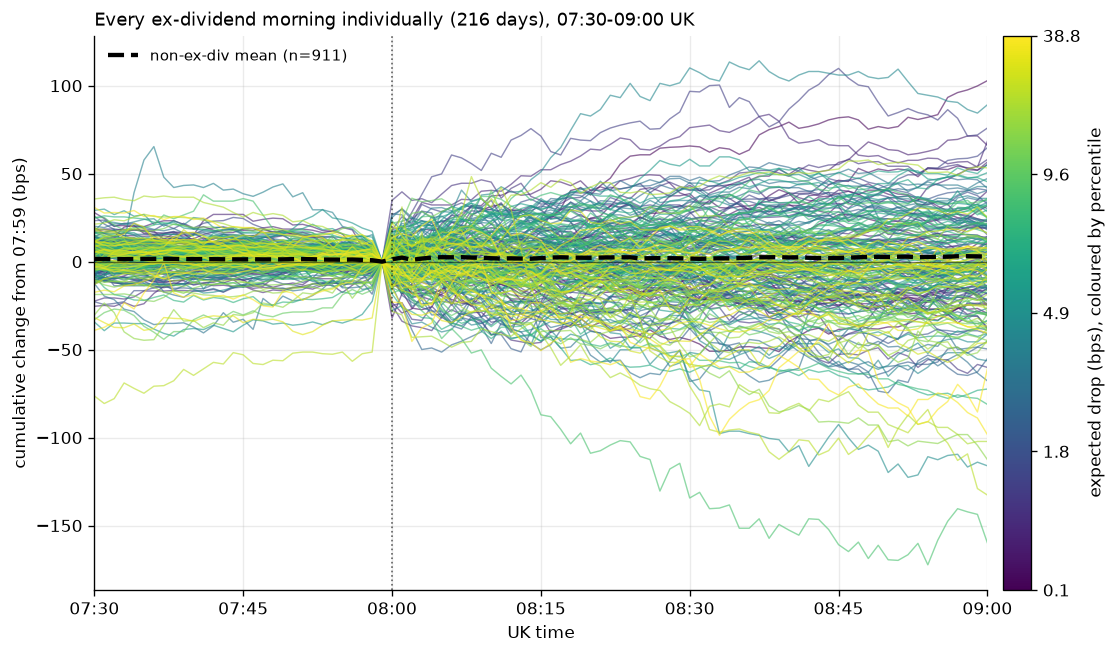

at 09:00, across the 216 ex-div days: mean -2.9 bps, median -1.1, sd 35.2, min -159.8, max +102.9
top quintile by expected drop: mean -18.4 bps, 70% ended below the rebase point
bottom quintile:               mean +9.6 bps, 42% ended below
non-ex-div mean at 09:00: +2.9 bps


In [ ]:
# ============ PLAY WITH THESE ============
IND_WHICH_DAY = "T"                    # "T" = ex-div morning, "T-1" = close before
IND_FROM, IND_TO = "07:30", "09:00"
IND_REBASE_AT = "07:59"                # None -> rebase at IND_FROM
IND_TICK_EVERY_MIN = 15
IND_SMOOTH_MIN = 1
COLOR_SCALE = "rank"                   # "rank" or "linear"
CMAP = "viridis"
SHOW_NONEX_MEAN = True
SHOW_EX_MEAN = False
LINE_ALPHA, LINE_WIDTH = 0.60, 0.85
# =========================================

if IND_WHICH_DAY not in ("T", "T-1"):
    raise ValueError('IND_WHICH_DAY must be "T" or "T-1"')
dcol = "drop_T" if IND_WHICH_DAY == "T" else "drop_T1"
ilo, ihi = uk_to_m(IND_FROM), uk_to_m(IND_TO)
if ilo >= ihi:
    raise ValueError("IND_FROM must be before IND_TO")
irb = ilo if IND_REBASE_AT is None else uk_to_m(IND_REBASE_AT)

drop_series = days[dcol].dropna()
ex_idx = drop_series.index[drop_series > 0]
ne_idx = drop_series.index[drop_series == 0]


def rebased(idx):
    'Per-day paths over the window, in bps relative to the rebase minute.'
    return (mid.loc[idx, ilo:ihi].div(mid.loc[idx, irb], axis=0) - 1.0) * 1e4


paths = rebased(ex_idx)
dv = drop_series.loc[ex_idx]

if COLOR_SCALE == "rank":
    cval, norm = dv.rank(pct=True), plt.Normalize(0.0, 1.0)
elif COLOR_SCALE == "linear":
    cval, norm = dv, plt.Normalize(0.0, float(dv.max()))
else:
    raise ValueError('COLOR_SCALE must be "rank" or "linear"')
cmap = plt.get_cmap(CMAP)

fig, ax = plt.subplots(figsize=(11.5, 6.0))
# draw low-drop days first so the heavy ones sit on top rather than being buried
for d_ in dv.sort_values().index:
    s = paths.loc[d_]
    if IND_SMOOTH_MIN > 1:
        s = s.rolling(IND_SMOOTH_MIN, center=True, min_periods=1).mean()
    ax.plot(s.index, s.to_numpy(), color=cmap(norm(cval[d_])),
            lw=LINE_WIDTH, alpha=LINE_ALPHA, zorder=2)

if SHOW_NONEX_MEAN and len(ne_idx):
    nm = rebased(ne_idx).mean(axis=0)
    if IND_SMOOTH_MIN > 1:
        nm = nm.rolling(IND_SMOOTH_MIN, center=True, min_periods=1).mean()
    ax.plot(nm.index, nm.to_numpy(), color="k", lw=2.6, ls="--", zorder=6,
            label=f"non-ex-div mean (n={len(ne_idx)})")
if SHOW_EX_MEAN:
    em = paths.mean(axis=0)
    if IND_SMOOTH_MIN > 1:
        em = em.rolling(IND_SMOOTH_MIN, center=True, min_periods=1).mean()
    ax.plot(em.index, em.to_numpy(), color="#c1121f", lw=2.6, zorder=6,
            label=f"ex-div mean (n={len(ex_idx)})")

ax.axhline(0, color="k", lw=0.8, alpha=0.5)
if ilo <= OPEN_M <= ihi:
    ax.axvline(OPEN_M, color="k", lw=1.0, ls=":", alpha=0.6)
if ilo <= CLOSE_M <= ihi:
    ax.axvline(CLOSE_M, color="#e76f51", lw=1.0, ls=":", alpha=0.6)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cb = fig.colorbar(sm, ax=ax, pad=0.015)
if COLOR_SCALE == "rank":
    qs = [0.0, 0.25, 0.5, 0.75, 1.0]
    cb.set_ticks(qs)
    cb.set_ticklabels([f"{dv.quantile(q):.1f}" for q in qs])
    cb.set_label("expected drop (bps), coloured by percentile")
else:
    cb.set_label("expected drop (bps)")

ticks = list(range(ilo + (-ilo) % IND_TICK_EVERY_MIN, ihi + 1, IND_TICK_EVERY_MIN))
ax.set_xticks(ticks)
ax.set_xticklabels([m_to_uk(m) for m in ticks])
ax.set_xlim(ilo, ihi)
ax.set_xlabel("UK time")
ax.set_ylabel(f"cumulative change from {m_to_uk(irb)} (bps)")
ax.set_title(f"Every {'ex-dividend morning' if IND_WHICH_DAY == 'T' else 'cum-div close'} "
             f"individually ({len(ex_idx)} days), {m_to_uk(ilo)}-{m_to_uk(ihi)} UK",
             loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9, loc="upper left")
plt.show()

# How much of the picture is a tendency vs a few days? Dispersion at the endpoint.
end = paths[ihi]
print(f"at {m_to_uk(ihi)}, across the {len(end)} ex-div days: "
      f"mean {end.mean():+.1f} bps, median {end.median():+.1f}, "
      f"sd {end.std(ddof=1):.1f}, min {end.min():+.1f}, max {end.max():+.1f}")
top = dv.nlargest(max(len(dv) // 5, 1)).index
print(f"top quintile by expected drop: mean {end.loc[top].mean():+.1f} bps, "
      f"{(end.loc[top] < 0).mean() * 100:.0f}% ended below the rebase point")
bot = dv.nsmallest(max(len(dv) // 5, 1)).index
print(f"bottom quintile:               mean {end.loc[bot].mean():+.1f} bps, "
      f"{(end.loc[bot] < 0).mean() * 100:.0f}% ended below")
if SHOW_NONEX_MEAN and len(ne_idx):
    print(f"non-ex-div mean at {m_to_uk(ihi)}: "
          f"{rebased(ne_idx)[ihi].mean():+.1f} bps")

## 10. Sharpe ratio — short at 08:00, parameter-selected exit

The trading version of section 5b. Set `TRADE_EXIT_TIME` in the parameter box to
change the exit for both the short-large and long-small backtests. A falling market
is profit for the short trade.

**Costs are measured, not assumed.** A short crosses the spread at both ends —
selling at the bid at 08:00, buying at the ask at 08:30 — so the cost is one full
round trip of half-spreads, charged **per day at that day's own spread**. Measured
across all 507 days: 1.94 ticks at 08:00 (0.52 bps half) and 1.63 ticks at 08:30
(0.44 bps half), so **~0.96 bps ≈ 0.89 index points ≈ £8.92 per lot** round trip.
Note the entry is at the *wider* moment of the two — being short into the open means
selling when the book is at its thinnest.

**Sharpe convention.** Returns are in bps of notional, annualised by
`sqrt(trades per year)`. No risk-free adjustment: the position is held 30 minutes a
day, so excess return is the raw return. This is the unlevered, fully-notional-funded
convention, which is what makes the number comparable to anything else.

In [ ]:
SPREAD_CACHE = Path(f"spread_0800_{TRADE_EXIT_TIME.replace(':', '')}.parquet")


def build_spreads(force=False):
    'Mean quoted spread in a +/-30s window around entry and selected exit.'
    if SPREAD_CACHE.exists() and not force:
        return pd.read_parquet(SPREAD_CACHE)
    rows = []
    for p in sorted(x for x in TICK_DIR.iterdir()
                    if x.is_dir() and x.name.isdigit()):
        day = pd.Timestamp(p.name)
        if day not in mid.index:
            continue
        f = front_month_file(p)
        if f is None:
            continue
        q = pd.read_csv(f, skiprows=2, header=None, names=TICK_COLS,
                        usecols=["UnixTs", "MsgType", "Bid", "Ask"],
                        low_memory=False)
        q = q[(q["MsgType"] == "Q") & q["Bid"].notna() & q["Ask"].notna()]
        r = {"date": day}
        for lbl, hh in (("open", dt.time(8, 0)), ("close", TRADE_EXIT_CLOCK)):
            t = uk_epoch(day, hh)
            w = q[(q["UnixTs"] >= t - 30) & (q["UnixTs"] < t + 30)]
            r[f"spr_{lbl}"] = float((w["Ask"] - w["Bid"]).mean()) if len(w) else np.nan
        rows.append(r)
    out = pd.DataFrame(rows).set_index("date")
    out.to_parquet(SPREAD_CACHE)
    return out


spreads = build_spreads()
bt = pd.DataFrame(index=mid.index)
bt["drop"] = days["drop_T"]
bt["gross_bps"] = -(mid[TRADE_EXIT_M] - mid[OPEN_M]) / mid[OPEN_M] * 1e4
bt["cost_bps"] = ((spreads["spr_open"] / 2 + spreads["spr_close"] / 2)
                  .reindex(mid.index) / mid[OPEN_M] * 1e4)
bt["net_bps"] = bt["gross_bps"] - bt["cost_bps"]
bt["pts"] = -(mid[TRADE_EXIT_M] - mid[OPEN_M])
bt["group"] = days["group_T"]


def years_covered(index):
    'Calendar span of the observations actually used in a statistic.'
    ix = pd.DatetimeIndex(index)
    if len(ix) < 2:
        return np.nan
    return max((ix.max() - ix.min()).days / 365.25, 1 / 365.25)


BT_YEARS = years_covered(bt.index)
first_net_date = bt["net_bps"].first_valid_index()
cost_start_text = (first_net_date.date().isoformat() if first_net_date is not None
                   else "none in selected range")
print(f"sample {bt.index.min().date()} .. {bt.index.max().date()} "
      f"({BT_YEARS:.2f} years); executable cost observations start "
      f"{cost_start_text}")
print(f"cost: {spreads['spr_open'].mean():.3f} pts at 08:00 + "
      f"{spreads['spr_close'].mean():.3f} at {TRADE_EXIT_TIME}  -> half-spreads total "
      f"{bt['cost_bps'].mean():.2f} bps = "
      f"GBP {bt['cost_bps'].mean() / 1e4 * mid[OPEN_M].mean() * POINT_VALUE_GBP:.2f} "
      f"per lot")


def stats_for(s, label):
    g, n = s["gross_bps"].dropna(), s["net_bps"].dropna()
    tpy = len(n) / years_covered(n.index)
    pt_sr = n.mean() / n.std(ddof=1)
    sr = pt_sr * np.sqrt(tpy)
    # Lo (2002) analytic SE of an annualised Sharpe under iid returns
    se = np.sqrt(tpy) * np.sqrt((1 + 0.5 * pt_sr ** 2) / len(n))
    return {"subset": label, "n": len(n), "per_yr": tpy,
            "gross_bps": g.mean(), "cost_bps": s["cost_bps"].mean(),
            "net_bps": n.mean(), "sd_bps": n.std(ddof=1),
            "hit_pct": (n > 0).mean() * 100,
            "sharpe_gross": g.mean() / g.std(ddof=1) * np.sqrt(tpy),
            "sharpe_net": sr, "sharpe_se": se,
            "t_net": n.mean() / (n.std(ddof=1) / np.sqrt(len(n))),
            "gbp_per_lot": n.mean() / 1e4 * mid[OPEN_M].mean() * POINT_VALUE_GBP,
            "ann_gbp_per_lot": n.mean() / 1e4 * mid[OPEN_M].mean()
                               * POINT_VALUE_GBP * tpy}


rows = [stats_for(bt, "ALL DAYS"),
        stats_for(bt[bt["drop"] > 0], "all ex-div days"),
        stats_for(bt[bt["group"] == "none"], "non-ex-div days")]
for g in ["small", "medium", "large"]:
    rows.append(stats_for(bt[bt["group"] == g], f"bucket: {g}"))
tbl = pd.DataFrame(rows).set_index("subset")
print(f"\nSHORT 08:00 -> COVER {TRADE_EXIT_TIME}\n")
print(tbl.round({"per_yr": 1, "gross_bps": 2, "cost_bps": 2, "net_bps": 2,
                 "sd_bps": 2, "hit_pct": 1, "sharpe_gross": 2, "sharpe_net": 2,
                 "sharpe_se": 2, "t_net": 2, "gbp_per_lot": 2,
                 "ann_gbp_per_lot": 0}).to_string())
bucket_net = tbl.loc[["bucket: small", "bucket: medium", "bucket: large"], "net_bps"]
print("\nBucket net means (bps): "
      + ", ".join(f"{name.removeprefix('bucket: ')} {value:+.2f}"
                  for name, value in bucket_net.items()))
print("Use the table rather than a hard-coded narrative: these values change with "
      "the selected date range, exit time and bucket definitions.")

sample 2022-03-03 .. 2026-08-20 (4.47 years); executable cost observations start 2022-03-03
cost: 0.878 pts at 08:00 + 0.756 at 10:00  -> half-spreads total 0.98 bps = GBP 8.22 per lot

SHORT 08:00 -> COVER 10:00

                    n  per_yr  gross_bps  cost_bps  net_bps  sd_bps  hit_pct  sharpe_gross  sharpe_net  sharpe_se  t_net  gbp_per_lot  ann_gbp_per_lot
subset                                                                                                                                                
ALL DAYS         1127   252.4       0.09      0.98    -0.89   37.48     48.3          0.04       -0.38       0.47  -0.80        -7.48          -1889.0
all ex-div days   216    48.4       5.55      0.98     4.57   38.64     52.3          1.00        0.82       0.47   1.74        38.32           1853.0
non-ex-div days   911   204.3      -1.21      0.98    -2.19   37.10     47.3         -0.46       -0.84       0.47  -1.78       -18.34          -3747.0
bucket: small      72    16.8  

### Does it depend on where the threshold is drawn?

The `large` tercile was fitted *after* seeing the data, so its Sharpe is
optimistically biased. The honest check is a grid of **fixed, ex-ante** thresholds:
if the result only works at one cut, it is curve-fitting. Bootstrap CIs (4,000
resamples) alongside the analytic Lo standard error.

In [ ]:
rng = np.random.default_rng(0)
rows = []
for thr in [2, 3, 4, 5, 6, 8, 10, 12]:
    s = bt.loc[bt["drop"] > thr, "gross_bps"].dropna()
    if len(s) < 8:
        continue
    tpy = len(s) / years_covered(s.index)
    pt = s.mean() / s.std(ddof=1)
    sr = pt * np.sqrt(tpy)
    boot = [pd.Series(rng.choice(s, len(s))).pipe(
        lambda x: x.mean() / x.std(ddof=1) * np.sqrt(tpy)) for _ in range(4000)]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    rows.append({"rule": f"drop > {thr} bps", "n": len(s), "per_yr": tpy,
                 "gross_bps": s.mean(), "hit_pct": (s > 0).mean() * 100,
                 "sharpe_gross": sr, "boot_lo": lo, "boot_hi": hi,
                 "lo_se": np.sqrt(tpy) * np.sqrt((1 + 0.5 * pt ** 2) / len(s)),
                 "t": s.mean() / (s.std(ddof=1) / np.sqrt(len(s)))})
thresh = pd.DataFrame(rows).set_index("rule")
print(thresh.round(2).to_string())
core = thresh.loc[[r for r in thresh.index
                   if 3 <= int(r.split()[2]) <= 12], "sharpe_gross"]
print(f"\nAcross thresholds from 3 to 12 bps the Sharpe stays in a "
      f"{core.min():.2f}-{core.max():.2f} band, and every one of those cuts has "
      f"t > {thresh.loc[core.index, 't'].min():.1f}.")
print("So the number is not an artefact of where the cut was drawn.")

                 n  per_yr  gross_bps  hit_pct  sharpe_gross  boot_lo  boot_hi  lo_se     t
rule                                                                                       
drop > 2 bps   159   35.61      10.49    58.49          1.61     0.74     2.48   0.48  3.41
drop > 3 bps   144   32.25      11.76    59.72          1.68     0.83     2.53   0.48  3.54
drop > 4 bps   122   27.44      14.80    62.30          1.94     1.09     2.77   0.49  4.08
drop > 5 bps   107   24.17      15.04    61.68          1.90     1.03     2.80   0.49  4.01
drop > 6 bps    96   21.68      16.77    63.54          1.94     1.10     2.82   0.50  4.09
drop > 8 bps    76   17.17      20.89    63.16          2.13     1.32     2.95   0.51  4.49
drop > 10 bps   52   11.75      24.52    69.23          2.02     1.32     2.85   0.51  4.25
drop > 12 bps   44    9.94      25.53    65.91          1.87     1.24     2.60   0.52  3.94

Across thresholds from 3 to 12 bps the Sharpe stays in a 1.68-2.13 band, and ev

threshold: expected drop > 5 bps  ->  107 trades (24.2/yr), mean gross +15.04 bps


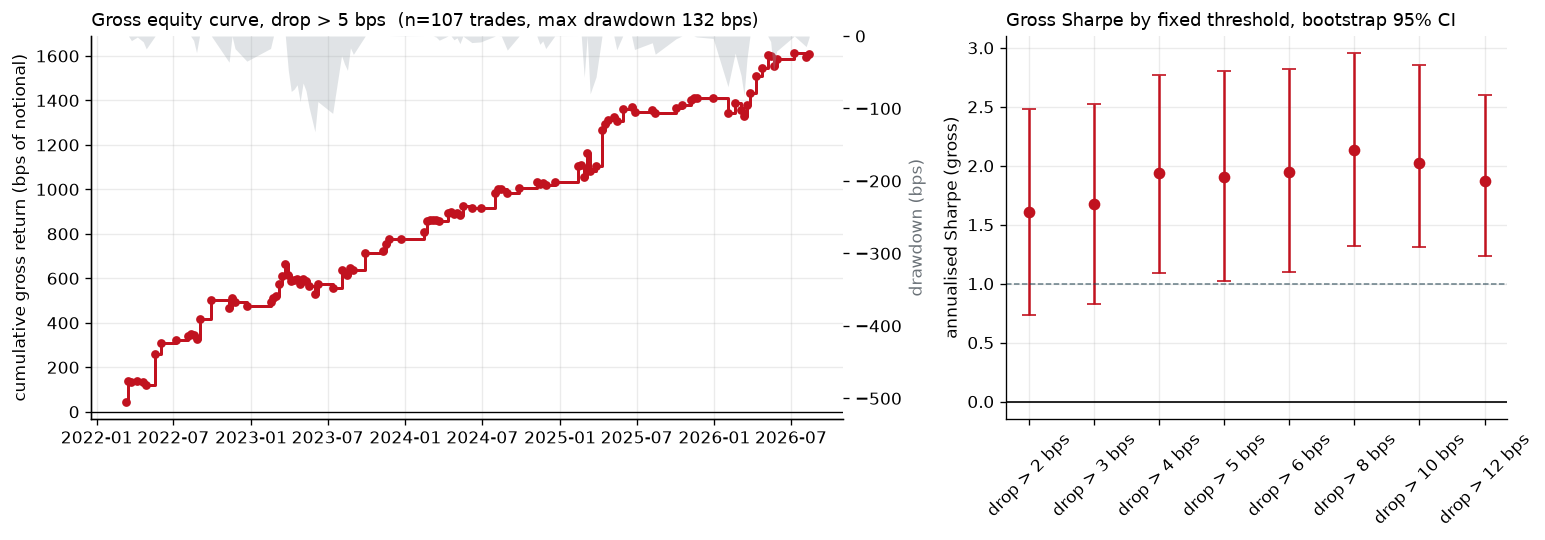

drop > 5 bps: cumulative 1610 bps | max drawdown 132 bps | worst trade -79.8 bps | longest losing streak 3

gross return by year:
      count   mean    std
date                     
2022     19  25.11  47.59
2023     27  11.13  32.50
2024     24  10.71  21.60
2025     22  17.01  50.14
2026     15  13.38  42.52


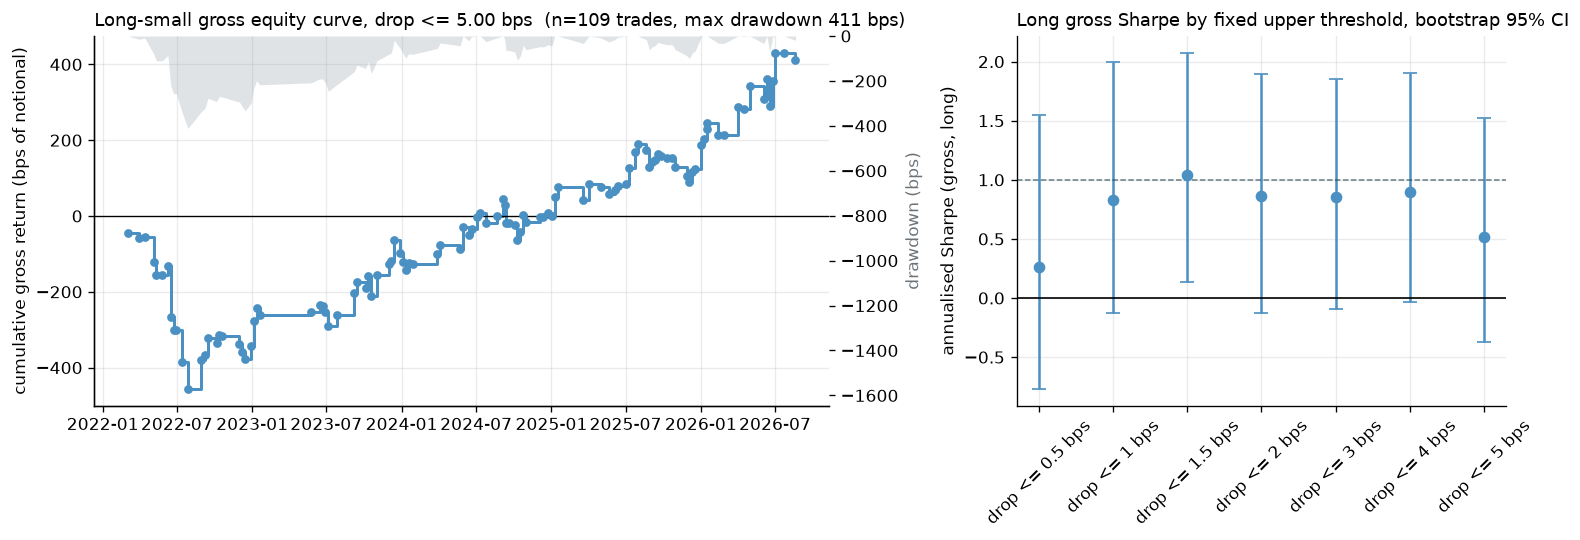

long small dates (drop <= 5.00 bps): cumulative 411 bps | mean +3.77 bps | max drawdown 411 bps | worst trade -134.4 bps

long-small gross return by year:
      count   mean    std
date                     
2022     22 -15.61  46.58
2023     19  12.89  35.28
2024     26   4.05  26.52
2025     26   4.53  24.48
2026     16  17.90  44.07

IN-SAMPLE flatten optimisation, 08:01-11:00 UK
short drop > 5 bps: best 09:58, Sharpe 1.91, mean +14.90 bps
long drop <= 5 bps: best 08:29, Sharpe 0.74, mean +3.71 bps

Top five short exits:
 exit   n  mean_bps  hit_pct  sharpe  cum_bps  max_dd_bps
09:58 107     14.90    61.68    1.91  1594.71      138.18
10:07 107     14.83    64.49    1.91  1587.20      111.36
10:00 107     15.04    61.68    1.90  1609.63      132.13
09:38 107     14.98    62.62    1.89  1602.62      137.09
09:55 107     14.43    60.75    1.89  1544.17      141.14

Top five long-small exits:
 exit   n  mean_bps  hit_pct  sharpe  cum_bps  max_dd_bps
08:29 109      3.71    49.54    0.74 

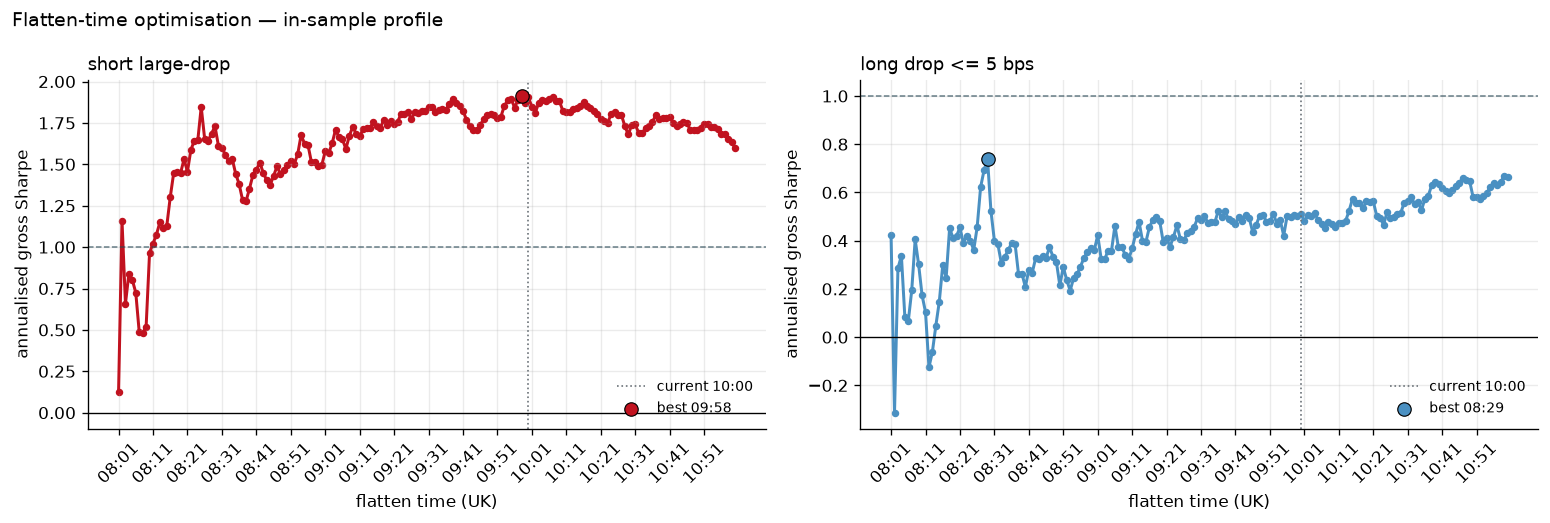

In [ ]:
# ============ EQUITY CURVE THRESHOLD ============
EQUITY_THRESHOLD_BPS = 5      # trade only when expected drop exceeds this
SMALL_MAX_DROP_BPS = 5        # None = small-bucket cut; e.g. 2.0 for 0 < drop <= 2
# ================================================
# Sanity: with too few trades an equity curve is decorative, not evidence.
sel = bt[bt["drop"] > EQUITY_THRESHOLD_BPS].dropna(subset=["gross_bps"]).sort_index()
if len(sel) < 5:
    raise ValueError(f"only {len(sel)} trades above "
                     f"{EQUITY_THRESHOLD_BPS} bps -- lower EQUITY_THRESHOLD_BPS")
sel_years = years_covered(sel.index)
print(f"threshold: expected drop > {EQUITY_THRESHOLD_BPS} bps  ->  {len(sel)} "
      f"trades ({len(sel) / sel_years:.1f}/yr), mean gross "
      f"{sel['gross_bps'].mean():+.2f} bps")
eq = sel["gross_bps"].cumsum()
dd = (eq.cummax() - eq)

fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.6),
                         gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
ax.step(eq.index, eq.to_numpy(), where="post", color="#c1121f", lw=1.8)
ax.scatter(sel.index, eq.to_numpy(), s=18, color="#c1121f", zorder=3)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("cumulative gross return (bps of notional)")
ax.set_title(f"Gross equity curve, drop > {EQUITY_THRESHOLD_BPS} bps  "
             f"(n={len(sel)} trades, max drawdown {dd.max():.0f} bps)",
             loc="left", fontsize=10.5)
ax2 = ax.twinx()
ax2.fill_between(eq.index, 0, -dd.to_numpy(), color="#9aa5ad", alpha=0.30, lw=0)
ax2.set_ylabel("drawdown (bps)", color="#6b7278")
ax2.set_ylim(-dd.max() * 4, 0)
ax2.grid(False)

ax = axes[1]
ax.errorbar(thresh.index, thresh["sharpe_gross"],
            yerr=[thresh["sharpe_gross"] - thresh["boot_lo"],
                  thresh["boot_hi"] - thresh["sharpe_gross"]],
            fmt="o", ms=6, capsize=4, color="#c1121f")
ax.axhline(0, color="k", lw=1.0)
ax.axhline(1, color="#264653", lw=0.9, ls="--", alpha=0.7)
ax.set_ylabel("annualised Sharpe (gross)")
ax.set_title("Gross Sharpe by fixed threshold, bootstrap 95% CI", loc="left",
             fontsize=10.5)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

streak = mx = 0
for v in sel["gross_bps"]:
    streak = streak + 1 if v < 0 else 0
    mx = max(mx, streak)
print(f"drop > {EQUITY_THRESHOLD_BPS} bps: cumulative {eq.iloc[-1]:.0f} bps | max drawdown "
      f"{dd.max():.0f} bps | worst trade {sel['gross_bps'].min():.1f} bps | "
      f"longest losing streak {mx}")
print("\ngross return by year:")
print(sel.groupby(sel.index.year)["gross_bps"]
      .agg(["count", "mean", "std"]).round(2).to_string())

# Mirror analysis for small ex-dividend days: buy at 08:00 and sell at the
# selected exit. The threshold can be fixed or inherited from the small bucket.
small_trade_cut = cuts[0] if SMALL_MAX_DROP_BPS is None else float(SMALL_MAX_DROP_BPS)
if small_trade_cut <= 0:
    raise ValueError("SMALL_MAX_DROP_BPS must be positive or None")
small_sel = bt[(bt["drop"] > 0) & (bt["drop"] <= small_trade_cut)] \
    .dropna(subset=["gross_bps"]).sort_index().copy()
small_sel["long_gross_bps"] = -small_sel["gross_bps"]
if len(small_sel) < 5:
    raise ValueError(f"only {len(small_sel)} small-bucket trades in the selected range")

small_eq = small_sel["long_gross_bps"].cumsum()
small_dd = small_eq.cummax() - small_eq

rng_small = np.random.default_rng(1)
small_rows = []
for thr in [0.5, 1, 1.5, 2, 3, 4, 5]:
    s = -bt.loc[(bt["drop"] > 0) & (bt["drop"] <= thr), "gross_bps"].dropna()
    if len(s) < 8:
        continue
    tpy = len(s) / years_covered(s.index)
    pt = s.mean() / s.std(ddof=1)
    sr = pt * np.sqrt(tpy)
    boot = [pd.Series(rng_small.choice(s, len(s))).pipe(
        lambda x: x.mean() / x.std(ddof=1) * np.sqrt(tpy)) for _ in range(4000)]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    small_rows.append({"rule": f"drop <= {thr:g} bps", "n": len(s),
                       "sharpe_gross": sr, "boot_lo": lo, "boot_hi": hi})
small_thresh = pd.DataFrame(small_rows).set_index("rule")

blue = "#4a90c2"
fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.6),
                         gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
ax.step(small_eq.index, small_eq.to_numpy(), where="post", color=blue, lw=1.8)
ax.scatter(small_sel.index, small_eq.to_numpy(), s=18, color=blue, zorder=3)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("cumulative gross return (bps of notional)")
ax.set_title(f"Long-small gross equity curve, drop <= {small_trade_cut:.2f} bps  "
             f"(n={len(small_sel)} trades, max drawdown {small_dd.max():.0f} bps)",
             loc="left", fontsize=10.5)
ax2 = ax.twinx()
ax2.fill_between(small_eq.index, 0, -small_dd.to_numpy(),
                 color="#9aa5ad", alpha=0.30, lw=0)
ax2.set_ylabel("drawdown (bps)", color="#6b7278")
ax2.set_ylim(-max(small_dd.max() * 4, 1), 0)
ax2.grid(False)

ax = axes[1]
ax.errorbar(small_thresh.index, small_thresh["sharpe_gross"],
            yerr=[small_thresh["sharpe_gross"] - small_thresh["boot_lo"],
                  small_thresh["boot_hi"] - small_thresh["sharpe_gross"]],
            fmt="o", ms=6, capsize=4, color=blue)
ax.axhline(0, color="k", lw=1.0)
ax.axhline(1, color="#264653", lw=0.9, ls="--", alpha=0.7)
ax.set_ylabel("annualised Sharpe (gross, long)")
ax.set_title("Long gross Sharpe by fixed upper threshold, bootstrap 95% CI",
             loc="left", fontsize=10.5)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

print(f"long small dates (drop <= {small_trade_cut:.2f} bps): cumulative "
      f"{small_eq.iloc[-1]:.0f} bps | mean {small_sel['long_gross_bps'].mean():+.2f} bps "
      f"| max drawdown {small_dd.max():.0f} bps | "
      f"worst trade {small_sel['long_gross_bps'].min():.1f} bps")
print("\nlong-small gross return by year:")
print(small_sel.groupby(small_sel.index.year)["long_gross_bps"]
      .agg(["count", "mean", "std"]).round(2).to_string())

# In-sample flatten-time profile. Gross returns keep every minute comparable
# over the selected date range without dependence on spread-cache coverage.
search_from_m = uk_to_m(FLATTEN_SEARCH_FROM)
search_to_m = uk_to_m(FLATTEN_SEARCH_TO)
if not OPEN_M < search_from_m <= search_to_m:
    raise ValueError("flatten search must start after 08:00 and end after it starts")


def flatten_stats(mask, exit_m, side):
    px_ret = (mid[exit_m] / mid[OPEN_M] - 1.0) * 1e4
    r = (side * px_ret).loc[mask].dropna()
    tpy = len(r) / years_covered(r.index)
    eq_ = r.cumsum()
    dd_ = eq_.cummax() - eq_
    return {"exit_m": exit_m, "exit": m_to_uk(exit_m), "n": len(r),
            "mean_bps": r.mean(), "hit_pct": (r > 0).mean() * 100,
            "sharpe": r.mean() / r.std(ddof=1) * np.sqrt(tpy),
            "cum_bps": r.sum(), "max_dd_bps": dd_.max()}


short_mask = bt["drop"] > EQUITY_THRESHOLD_BPS
small_mask = (bt["drop"] > 0) & (bt["drop"] <= small_trade_cut)
short_flatten = pd.DataFrame([
    flatten_stats(short_mask, m_, -1)
    for m_ in range(search_from_m, search_to_m + 1)
]).set_index("exit_m")
small_flatten = pd.DataFrame([
    flatten_stats(small_mask, m_, +1)
    for m_ in range(search_from_m, search_to_m + 1)
]).set_index("exit_m")

best_short_m = short_flatten["sharpe"].idxmax()
best_small_m = small_flatten["sharpe"].idxmax()
print(f"\nIN-SAMPLE flatten optimisation, {FLATTEN_SEARCH_FROM}-{FLATTEN_SEARCH_TO} UK")
print(f"short drop > {EQUITY_THRESHOLD_BPS:g} bps: best {m_to_uk(best_short_m)}, "
      f"Sharpe {short_flatten.loc[best_short_m, 'sharpe']:.2f}, mean "
      f"{short_flatten.loc[best_short_m, 'mean_bps']:+.2f} bps")
print(f"long drop <= {small_trade_cut:g} bps: best {m_to_uk(best_small_m)}, "
      f"Sharpe {small_flatten.loc[best_small_m, 'sharpe']:.2f}, mean "
      f"{small_flatten.loc[best_small_m, 'mean_bps']:+.2f} bps")
print("\nTop five short exits:")
print(short_flatten.nlargest(5, "sharpe")
      [["exit", "n", "mean_bps", "hit_pct", "sharpe", "cum_bps", "max_dd_bps"]]
      .round(2).to_string(index=False))
print("\nTop five long-small exits:")
print(small_flatten.nlargest(5, "sharpe")
      [["exit", "n", "mean_bps", "hit_pct", "sharpe", "cum_bps", "max_dd_bps"]]
      .round(2).to_string(index=False))
print("\nWARNING: the best minute is selected on the same data used to score it; "
      "treat it as exploratory until tested out of sample.")

fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.4))
for ax, frame, color, label, best_m in [
        (axes[0], short_flatten, "#c1121f", "short large-drop", best_short_m),
        (axes[1], small_flatten, "#4a90c2",
         f"long drop <= {small_trade_cut:g} bps", best_small_m)]:
    ax.plot(frame.index, frame["sharpe"], color=color, lw=1.8)
    ax.scatter(frame.index, frame["sharpe"], color=color, s=12)
    ax.axhline(0, color="k", lw=0.8)
    ax.axhline(1, color="#264653", lw=0.9, ls="--", alpha=0.7)
    ax.axvline(TRADE_EXIT_M, color="#6b7278", lw=1.0, ls=":",
               label=f"current {TRADE_EXIT_TIME}")
    ax.scatter([best_m], [frame.loc[best_m, "sharpe"]], color=color,
               s=65, edgecolor="black", linewidth=0.7, zorder=4,
               label=f"best {m_to_uk(best_m)}")
    ticks_ = list(range(search_from_m, search_to_m + 1, 10))
    ax.set_xticks(ticks_)
    ax.set_xticklabels([m_to_uk(m_) for m_ in ticks_], rotation=45)
    ax.set_xlabel("flatten time (UK)")
    ax.set_ylabel("annualised gross Sharpe")
    ax.set_title(label, loc="left", fontsize=10.5)
    ax.legend(frameon=False, fontsize=8.5)
fig.suptitle("Flatten-time optimisation — in-sample profile", x=0.01,
             ha="left", fontsize=11.5)
fig.tight_layout()
plt.show()

## 11. Dynamic DAX hedge — removing the general European equity move

This is a separate overlay on the parameter-selected strategy window. The DAX leg
uses the same elapsed interval from 09:00 Berlin, including through the BST/CET
clock changes. For each date, estimate the historical relationship

```
FTSE return = alpha + beta x DAX return + residual
```

from the **previous 60 common non-FTSE-ex-dividend sessions only**. The current day
is never included, so the ratio is known at 08:00 and has no look-ahead. The hedged
trade is therefore

```
short 1.00 FTSE notional + long beta DAX notional
hedged P&L (bps of FTSE notional) = -FTSE return + beta x DAX return
```

For the long-small rule the directions are reversed:

```
long 1.00 FTSE notional + short beta DAX notional
hedged P&L (bps of FTSE notional) = FTSE return - beta x DAX return
```

DAX is a performance index, so constituent dividends are reinvested rather than
causing the mechanical price-index drop being studied in FTSE. A 120-session ratio
and an expanding ratio are shown as sensitivity checks. The headline performance
also charges the observed bid/ask half-spread at both legs and both endpoints.

The ratio below is a **notional** ratio, not a one-for-one contract ratio. `EURGBP`
is reconstructed separately for every event from synchronized, same-expiry CME 6E
and 6B quotes: `EURGBP = 6E / 6B`. The latest quote at or before the timestamp is
used, never a later quote. For full contracts:

```
DAX contracts per FTSE contract
    = beta x (FTSE level x GBP 10)
           / (DAX level x EUR 25 x EURGBP at entry)
```

For Mini-DAX replace EUR 25 with EUR 5; for Micro-DAX replace it with EUR 1.
The beta remains a regression of local-currency index returns; FX is used only to
size contracts and translate the DAX leg's EUR P&L into GBP.

In [ ]:
DAX_PANEL_CACHE = Path("../DAX/dax_panel_with_mid.parquet")
DAX_OPEN_M = 9 * 60
DAX_SPREAD_CACHE = Path(
    f"../DAX/dax_spread_0900_{(DAX_OPEN_M + TRADE_HOLD_MINUTES) // 60:02d}"
    f"{(DAX_OPEN_M + TRADE_HOLD_MINUTES) % 60:02d}.parquet")
DAX_TICK_DIR = Path(r"D:\tick_data\100_ms\DAX")
FX_TICK_ROOT = Path(r"D:\tick_data\100_ms")
FX_CACHE = Path(
    f"eurgbp_6e6b_0800_{TRADE_EXIT_TIME.replace(':', '')}.parquet")
BERLIN = ZoneInfo("Europe/Berlin")
DAX_EXIT_M = DAX_OPEN_M + TRADE_HOLD_MINUTES
HEDGE_WINDOW = 60
HEDGE_MIN_OBS = 40

dax_panel = pd.read_parquet(DAX_PANEL_CACHE)
dax_mid = dax_panel.pivot_table(index="date", columns="m", values="mid")
dax_mid.index = pd.to_datetime(dax_mid.index)

# Use the full cached FTSE history to train the hedge ratio before the active
# event study begins.  Event results below are still restricted to analysis_start.
hedge_ft_panel = pd.read_parquet(PANEL_CACHE)
hedge_ft_panel["date"] = pd.to_datetime(hedge_ft_panel["date"])
hedge_ft_mid = hedge_ft_panel.pivot_table(index="date", columns="m", values="mid")

common = hedge_ft_mid.index.intersection(dax_mid.index).sort_values()
hedge = pd.DataFrame(index=common)
hedge["ftse_bps"] = ((hedge_ft_mid.loc[common, TRADE_EXIT_M] /
                       hedge_ft_mid.loc[common, OPEN_M]) - 1) * 1e4
hedge["dax_bps"] = ((dax_mid.loc[common, DAX_EXIT_M] /
                      dax_mid.loc[common, DAX_OPEN_M]) - 1) * 1e4
hedge["drop"] = exdiv["drop_bps"].reindex(common).fillna(0.0)
hedge["group"] = days["group_T"].reindex(common)

# FX is needed only on executable event dates. It does not enter beta training.
event_fx_dates = common.intersection(exdiv.index)
event_fx = eurgbp_history(
    event_fx_dates,
    cache=FX_CACHE,
    tick_root=FX_TICK_ROOT,
    entry_time=dt.time(8, 0),
    exit_time=TRADE_EXIT_CLOCK,
)
hedge = hedge.join(event_fx[["eurgbp_entry", "eurgbp_exit", "fx_contract",
                             "fx_entry_max_age_s", "fx_exit_max_age_s"]])
hedge["eurgbp_pnl_factor"] = hedge["eurgbp_exit"] / hedge["eurgbp_entry"]
# Historical ex-dividend labels before the active range may be incomplete.
# Exclude all Thursdays there; within the active range use the explicit labels.
hedge["training_normal"] = np.where(
    hedge.index < analysis_start,
    hedge.index.day_name() != "Thursday",
    hedge["drop"].eq(0.0),
)


def trailing_beta(frame, window=None, min_obs=HEDGE_MIN_OBS):
    'Lagged OLS slope FTSE~DAX; fit only prior, non-event observations.'
    out = pd.Series(np.nan, index=frame.index, dtype=float)
    eligible = frame["training_normal"] & frame[["ftse_bps", "dax_bps"]].notna().all(axis=1)
    for i, day in enumerate(frame.index):
        hist = frame.iloc[:i].loc[eligible.iloc[:i], ["ftse_bps", "dax_bps"]]
        if window is not None:
            hist = hist.tail(window)
        if len(hist) < min_obs or hist["dax_bps"].var(ddof=1) <= 0:
            continue
        out.loc[day] = hist["ftse_bps"].cov(hist["dax_bps"]) / \
            hist["dax_bps"].var(ddof=1)
    return out


hedge["beta_60"] = trailing_beta(hedge, 60)
hedge["beta_120"] = trailing_beta(hedge, 120)
hedge["beta_expanding"] = trailing_beta(hedge, None)
hedge["unhedged_gross_bps"] = -hedge["ftse_bps"]
hedge["long_unhedged_gross_bps"] = hedge["ftse_bps"]
for c in ["beta_60", "beta_120", "beta_expanding"]:
    hedge[f"hedged_{c}_gross_bps"] = (-hedge["ftse_bps"] +
                                       hedge[c] * hedge["dax_bps"]
                                       * hedge["eurgbp_pnl_factor"])
    hedge[f"long_hedged_{c}_gross_bps"] = (hedge["ftse_bps"] -
                                            hedge[c] * hedge["dax_bps"]
                                            * hedge["eurgbp_pnl_factor"])

# Full-size FDAX equivalents per FTSE contract, before integer rounding.
hedge["fdax_per_ftse_beta_60"] = (
    hedge["beta_60"] * hedge_ft_mid.loc[common, OPEN_M] * POINT_VALUE_GBP
    / (dax_mid.loc[common, DAX_OPEN_M] * 25.0 * hedge["eurgbp_entry"])
)

active_hedge = hedge[hedge.index >= analysis_start]
print(f"common FTSE/DAX history: {len(hedge)} sessions; "
      f"{hedge.index.min().date()} .. {hedge.index.max().date()}")
print(f"active common sessions: {len(active_hedge)}; "
      f"{active_hedge.index.min().date()} .. {active_hedge.index.max().date()}")
print(f"60-session beta available on {active_hedge['beta_60'].notna().sum()} active dates; "
      f"median {hedge['beta_60'].median():.3f}, "
      f"range {hedge['beta_60'].min():.3f} .. {hedge['beta_60'].max():.3f}")
latest_beta_date = hedge["beta_60"].last_valid_index()
print(f"latest available ratio ({latest_beta_date.date()}): "
      f"long {hedge.loc[latest_beta_date, 'beta_60']:.3f} DAX notional "
      f"per 1.000 FTSE notional short")
fx_ok = hedge["eurgbp_entry"].notna() & hedge["eurgbp_exit"].notna()
print(f"event-specific 6E/6B FX available on {fx_ok.sum()} dates; "
      f"entry EURGBP range {hedge.loc[fx_ok, 'eurgbp_entry'].min():.4f} .. "
      f"{hedge.loc[fx_ok, 'eurgbp_entry'].max():.4f}; "
      f"maximum quote age {hedge.loc[fx_ok, ['fx_entry_max_age_s', 'fx_exit_max_age_s']].max().max():.3f}s")

common FTSE/DAX history: 1664 sessions; 2020-01-02 .. 2026-08-20
active common sessions: 1120; 2022-03-03 .. 2026-08-20
60-session beta available on 1120 active dates; median 0.560, range 0.183 .. 0.890
latest available ratio (2026-08-20): long 0.623 DAX notional per 1.000 FTSE notional short
event-specific 6E/6B FX available on 214 dates; entry EURGBP range 0.8240 .. 0.8986; maximum quote age 4.974s


In [ ]:
def berlin_epoch(day, when):
    local = dt.datetime.combine(pd.Timestamp(day).date(), when, tzinfo=BERLIN)
    return (pd.Timestamp(local).tz_convert("UTC").tz_localize(None)
            - EPOCH) / pd.Timedelta(seconds=1)


def dax_front_month_file(day_dir):
    files = list(day_dir.glob("FUT_DAX*.csv"))
    if not files:
        return None
    best = max(files, key=lambda p: p.stat().st_size)
    return best if best.stat().st_size > 100_000 else None


def build_dax_spreads(force=False):
    'Mean DAX quoted spread in +/-30s around entry and selected exit.'
    if DAX_SPREAD_CACHE.exists() and not force:
        return pd.read_parquet(DAX_SPREAD_CACHE)
    rows = []
    for day in common:
        day_dir = DAX_TICK_DIR / day.strftime("%Y%m%d")
        f = dax_front_month_file(day_dir) if day_dir.exists() else None
        if f is None:
            continue
        q = pd.read_csv(f, skiprows=2, header=None, names=TICK_COLS,
                        usecols=["UnixTs", "MsgType", "Bid", "Ask"],
                        low_memory=False)
        q = q[(q["MsgType"] == "Q") & q["Bid"].notna() & q["Ask"].notna()]
        row = {"date": day}
        dax_exit_clock = dt.time(DAX_EXIT_M // 60, DAX_EXIT_M % 60)
        for label, when in (("open", dt.time(9, 0)), ("close", dax_exit_clock)):
            stamp = berlin_epoch(day, when)
            w = q[(q["UnixTs"] >= stamp - 30) & (q["UnixTs"] < stamp + 30)]
            row[f"spr_{label}"] = ((w["Ask"] - w["Bid"]).mean()
                                    if len(w) else np.nan)
        rows.append(row)
    out = pd.DataFrame(rows).set_index("date")
    out.to_parquet(DAX_SPREAD_CACHE)
    return out


dax_spreads = build_dax_spreads()
hedge["ftse_cost_bps"] = bt["cost_bps"].reindex(hedge.index)
hedge["dax_cost_per_dax_notional_bps"] = (
    (dax_spreads["spr_open"] / 2
     + dax_spreads["spr_close"] / 2 * hedge["eurgbp_pnl_factor"])
    / dax_mid.loc[dax_spreads.index, DAX_OPEN_M] * 1e4
).reindex(hedge.index)

for c in ["beta_60", "beta_120", "beta_expanding"]:
    hedge[f"hedged_{c}_net_bps"] = (
        hedge[f"hedged_{c}_gross_bps"] - hedge["ftse_cost_bps"]
        - hedge[c].abs() * hedge["dax_cost_per_dax_notional_bps"]
    )
    hedge[f"long_hedged_{c}_net_bps"] = (
        hedge[f"long_hedged_{c}_gross_bps"] - hedge["ftse_cost_bps"]
        - hedge[c].abs() * hedge["dax_cost_per_dax_notional_bps"]
    )
hedge["unhedged_net_bps"] = hedge["unhedged_gross_bps"] - hedge["ftse_cost_bps"]
hedge["long_unhedged_net_bps"] = (
    hedge["long_unhedged_gross_bps"] - hedge["ftse_cost_bps"]
)

print(f"mean DAX round-trip spread cost: "
      f"{hedge['dax_cost_per_dax_notional_bps'].mean():.2f} bps per unit DAX notional")
print(f"mean total cost with 60-session hedge: "
      f"{(hedge['ftse_cost_bps'] + hedge['beta_60'].abs() * hedge['dax_cost_per_dax_notional_bps']).mean():.2f} "
      f"bps of FTSE notional")

mean DAX round-trip spread cost: 1.16 bps per unit DAX notional
mean total cost with 60-session hedge: 1.55 bps of FTSE notional


In [ ]:
def hedge_summary(frame, gross_col, net_col, label):
    x = frame[[gross_col, net_col]].dropna()
    n = x[net_col]
    tpy = len(n) / years_covered(n.index)
    return {"series": label, "n": len(n), "gross_bps": x[gross_col].mean(),
            "net_bps": n.mean(), "sd_bps": n.std(ddof=1),
            "hit_pct": (n > 0).mean() * 100,
            "sharpe_net": n.mean() / n.std(ddof=1) * np.sqrt(tpy),
            "t_net": n.mean() / (n.std(ddof=1) / np.sqrt(len(n)))}


available = hedge[(hedge.index >= analysis_start) & hedge["beta_60"].notna()].copy()
subsets = {
    "all ex-div": available[available["drop"] > 0],
    "large bucket": available[available["group"] == "large"],
    f"drop > {EQUITY_THRESHOLD_BPS} bps":
        available[available["drop"] > EQUITY_THRESHOLD_BPS],
}
rows = []
for subset_name, sample in subsets.items():
    rows.append({"subset": subset_name, **hedge_summary(
        sample, "unhedged_gross_bps", "unhedged_net_bps", "unhedged")})
    for beta_name, label in [("beta_60", "DAX hedge: trailing 60"),
                             ("beta_120", "DAX hedge: trailing 120"),
                             ("beta_expanding", "DAX hedge: expanding")]:
        rows.append({"subset": subset_name, **hedge_summary(
            sample, f"hedged_{beta_name}_gross_bps",
            f"hedged_{beta_name}_net_bps", label)})
hedge_tbl = pd.DataFrame(rows).set_index(["subset", "series"])
print(hedge_tbl.round(2).to_string())

event = subsets[f"drop > {EQUITY_THRESHOLD_BPS} bps"].dropna(
    subset=["unhedged_net_bps", "hedged_beta_60_net_bps"])
if len(event) >= 3:
    vr = 1 - event["hedged_beta_60_gross_bps"].var(ddof=1) / \
        event["unhedged_gross_bps"].var(ddof=1)
    paired = event["hedged_beta_60_net_bps"] - event["unhedged_net_bps"]
    print(f"\nOn drop > {EQUITY_THRESHOLD_BPS} bps dates, the 60-session hedge reduces "
          f"gross variance by {vr:.1%} and changes average net P&L by "
          f"{paired.mean():+.2f} bps/trade.")

long_event = available[
    (available["drop"] > 0) & (available["drop"] <= small_trade_cut)
].dropna(subset=["long_unhedged_net_bps", "long_hedged_beta_60_net_bps"])
long_rows = [hedge_summary(
    long_event, "long_unhedged_gross_bps", "long_unhedged_net_bps", "unhedged long"
)]
for beta_name, label in [("beta_60", "DAX hedge: trailing 60"),
                         ("beta_120", "DAX hedge: trailing 120"),
                         ("beta_expanding", "DAX hedge: expanding")]:
    long_rows.append(hedge_summary(
        long_event, f"long_hedged_{beta_name}_gross_bps",
        f"long_hedged_{beta_name}_net_bps", label))
long_hedge_tbl = pd.DataFrame(long_rows).set_index("series")
print(f"\nLONG SMALL: 0 < expected drop <= {small_trade_cut:.2f} bps")
print(long_hedge_tbl.round(2).to_string())

if len(long_event) >= 3:
    long_vr = 1 - long_event["long_hedged_beta_60_gross_bps"].var(ddof=1) / \
        long_event["long_unhedged_gross_bps"].var(ddof=1)
    long_paired = (long_event["long_hedged_beta_60_net_bps"] -
                   long_event["long_unhedged_net_bps"])
    print(f"\nOn 0 < drop <= {small_trade_cut:.2f} bps dates, the 60-session DAX hedge "
          f"reduces gross variance by {long_vr:.1%} and changes average net P&L by "
          f"{long_paired.mean():+.2f} bps/trade.")

                                        n  gross_bps  net_bps  sd_bps  hit_pct  sharpe_net  t_net
subset       series                                                                              
all ex-div   unhedged                 214       5.61     4.63   38.80    52.34        0.83   1.75
             DAX hedge: trailing 60   214       3.64     2.09   29.12    49.53        0.50   1.05
             DAX hedge: trailing 120  214       3.46     1.91   28.74    49.07        0.46   0.97
             DAX hedge: expanding     214       2.60     0.83   29.97    50.00        0.19   0.41
large bucket unhedged                  72      21.48    20.46   40.25    63.89        2.05   4.31
             DAX hedge: trailing 60    72      17.41    15.74   28.95    72.22        2.19   4.61
             DAX hedge: trailing 120   72      17.07    15.41   27.89    73.61        2.23   4.69
             DAX hedge: expanding      72      15.00    13.11   30.52    72.22        1.73   3.64
drop > 5 bps unhedge

60-session DAX-hedged relationship: n = 214 ex-dividend dates

Pearson  r   = +0.276   p = 0.0000
Spearman rho = +0.360   p = 0.0000
Kendall  tau = +0.244   p = 0.0000

slope (lambda) = +1.037 +/- 0.249   t = +4.17   p = 0.0000
y-intercept (expected = 0) = -4.18 bps
x-intercept (actual = 0)   = +4.03 bps
R^2 = 0.076
reference: non-ex-div hedged 08:00-10:00 drop averages -0.67 bps (sd 28.0)


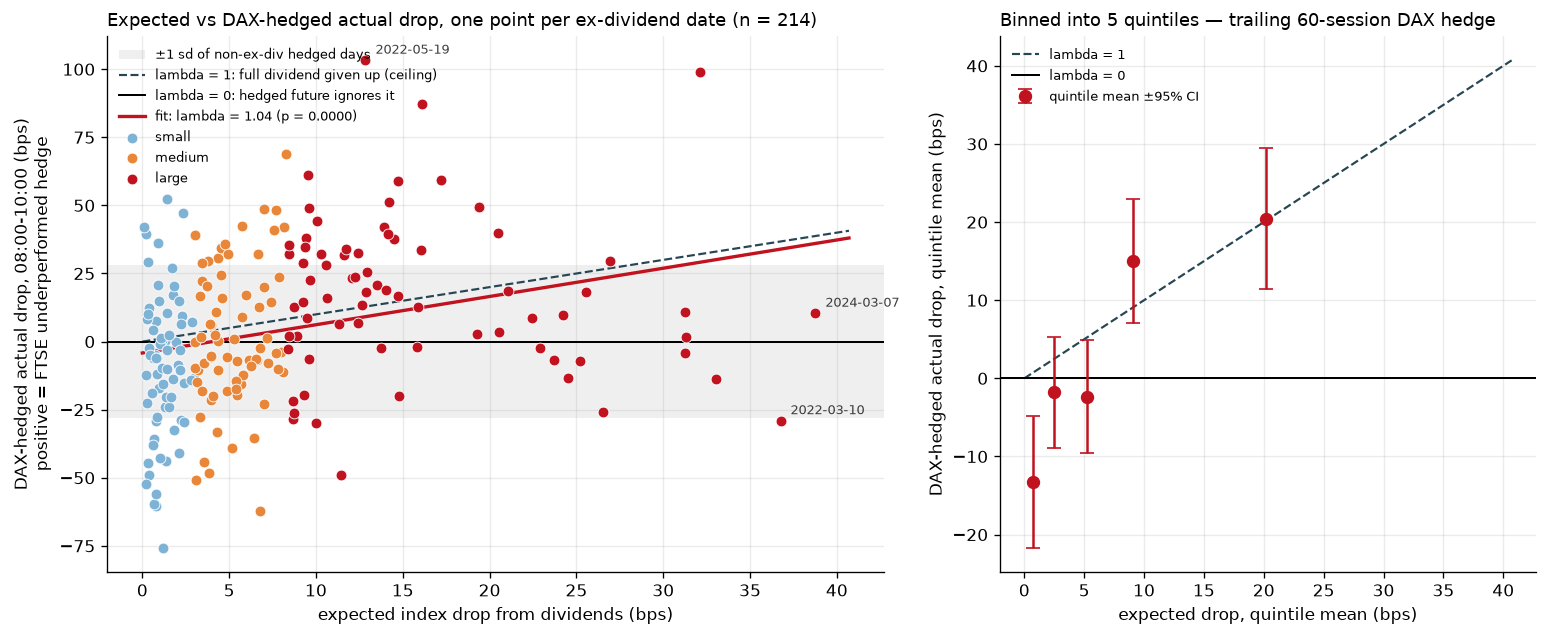

DAX-hedged quintiles of expected drop:
        n  exp_mean  act_mean  act_sd  pct_fell    se  t_vs_0
quint                                                        
0      43      0.73    -13.27   28.10      33.0  4.29   -3.10
1      43      2.50     -1.80   23.82      42.0  3.63   -0.50
2      42      5.20     -2.33   23.85      43.0  3.68   -0.63
3      43      9.04     15.02   26.76      70.0  4.08    3.68
4      43     20.21     20.45   30.11      74.0  4.59    4.45


In [ ]:
# Expected dividend drop versus the market-neutral FTSE drop after applying the
# strictly lagged 60-session DAX beta. Positive means FTSE underperformed DAX.
hedged_actual_drop = -hedge["ftse_bps"] + hedge["beta_60"] * hedge["dax_bps"]
hedge_active = ((hedge.index >= analysis_start) & (hedge.index <= analysis_end))
hedged_sc = pd.DataFrame({
    "expected": hedge["drop"],
    "actual": hedged_actual_drop,
    "group": hedge["group"],
}).loc[hedge_active & hedge["drop"].gt(0)].dropna(subset=["expected", "actual"])
hedged_nonex = hedged_actual_drop.loc[
    hedge_active & hedge["drop"].eq(0)].dropna()

hedged_fit = stats.linregress(hedged_sc["expected"], hedged_sc["actual"])
hedged_pear = stats.pearsonr(hedged_sc["expected"], hedged_sc["actual"])
hedged_spear = stats.spearmanr(hedged_sc["expected"], hedged_sc["actual"])
hedged_kend = stats.kendalltau(hedged_sc["expected"], hedged_sc["actual"])
hedged_x_intercept = (-hedged_fit.intercept / hedged_fit.slope
                      if not np.isclose(hedged_fit.slope, 0.0) else np.nan)

print(f"60-session DAX-hedged relationship: n = {len(hedged_sc)} ex-dividend dates\n")
print(f"Pearson  r   = {hedged_pear[0]:+.3f}   p = {hedged_pear[1]:.4f}")
print(f"Spearman rho = {hedged_spear[0]:+.3f}   p = {hedged_spear[1]:.4f}")
print(f"Kendall  tau = {hedged_kend[0]:+.3f}   p = {hedged_kend[1]:.4f}")
print(f"\nslope (lambda) = {hedged_fit.slope:+.3f} +/- {hedged_fit.stderr:.3f}   "
      f"t = {hedged_fit.slope / hedged_fit.stderr:+.2f}   "
      f"p = {hedged_fit.pvalue:.4f}")
print(f"y-intercept (expected = 0) = {hedged_fit.intercept:+.2f} bps")
print(f"x-intercept (actual = 0)   = {hedged_x_intercept:+.2f} bps")
print(f"R^2 = {hedged_fit.rvalue ** 2:.3f}")
print(f"reference: non-ex-div hedged 08:00-{TRADE_EXIT_TIME} drop averages "
      f"{hedged_nonex.mean():+.2f} bps (sd {hedged_nonex.std():.1f})")

hedged_sc["quint"] = pd.qcut(hedged_sc["expected"], QN, labels=False)
hedged_qt = hedged_sc.groupby("quint").agg(
    n=("expected", "size"), exp_mean=("expected", "mean"),
    act_mean=("actual", "mean"), act_sd=("actual", "std"),
    pct_fell=("actual", lambda s: (s > 0).mean() * 100))
hedged_qt["se"] = hedged_qt["act_sd"] / np.sqrt(hedged_qt["n"])
hedged_qt["t_vs_0"] = hedged_qt["act_mean"] / hedged_qt["se"]

fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.4),
                         gridspec_kw={"width_ratios": [1.45, 1]})
ax = axes[0]
hedged_xs = np.linspace(0, hedged_sc["expected"].max() * 1.05, 100)
ax.axhspan(-hedged_nonex.std(), hedged_nonex.std(), color="#b0b0b0",
           alpha=0.20, lw=0, zorder=0, label="±1 sd of non-ex-div hedged days")
ax.plot(hedged_xs, hedged_xs, color="#264653", lw=1.3, ls="--",
        label="lambda = 1: full dividend given up (ceiling)")
ax.axhline(0, color="k", lw=1.2, label="lambda = 0: hedged future ignores it")
ax.plot(hedged_xs, hedged_fit.intercept + hedged_fit.slope * hedged_xs,
        color="#c1121f", lw=2.0,
        label=f"fit: lambda = {hedged_fit.slope:.2f} (p = {hedged_fit.pvalue:.4f})")
for g in GROUP_ORDER[1:]:
    sample = hedged_sc[hedged_sc["group"] == g]
    ax.scatter(sample["expected"], sample["actual"], s=42, color=GCOL[g],
               edgecolor="white", linewidth=0.5, zorder=3, label=g)
for lbl in hedged_sc.nlargest(2, "expected").index.union(
        hedged_sc.nlargest(1, "actual").index):
    ax.annotate(lbl.strftime("%Y-%m-%d"),
                xy=(hedged_sc.loc[lbl, "expected"], hedged_sc.loc[lbl, "actual"]),
                xytext=(6, 4), textcoords="offset points", fontsize=7.5, alpha=0.75)
ax.set_xlabel("expected index drop from dividends (bps)")
ax.set_ylabel(f"DAX-hedged actual drop, 08:00-{TRADE_EXIT_TIME} (bps)\n"
              "positive = FTSE underperformed hedge")
ax.set_title(f"Expected vs DAX-hedged actual drop, one point per ex-dividend date "
             f"(n = {len(hedged_sc)})", loc="left", fontsize=10.5)
ax.legend(frameon=False, fontsize=7.8, loc="upper left")

ax = axes[1]
ax.errorbar(hedged_qt["exp_mean"], hedged_qt["act_mean"],
            yerr=1.96 * hedged_qt["se"], fmt="o", ms=7, capsize=4,
            color="#c1121f", zorder=3, label="quintile mean ±95% CI")
ax.plot(hedged_xs, hedged_xs, color="#264653", lw=1.3, ls="--", label="lambda = 1")
ax.axhline(0, color="k", lw=1.2, label="lambda = 0")
ax.set_xlabel("expected drop, quintile mean (bps)")
ax.set_ylabel("DAX-hedged actual drop, quintile mean (bps)")
ax.set_title(f"Binned into {QN} quintiles — trailing 60-session DAX hedge",
             loc="left", fontsize=10.5)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

print("DAX-hedged quintiles of expected drop:")
print(hedged_qt.round({"exp_mean": 2, "act_mean": 2, "act_sd": 2,
                        "se": 2, "t_vs_0": 2, "pct_fell": 0}).to_string())

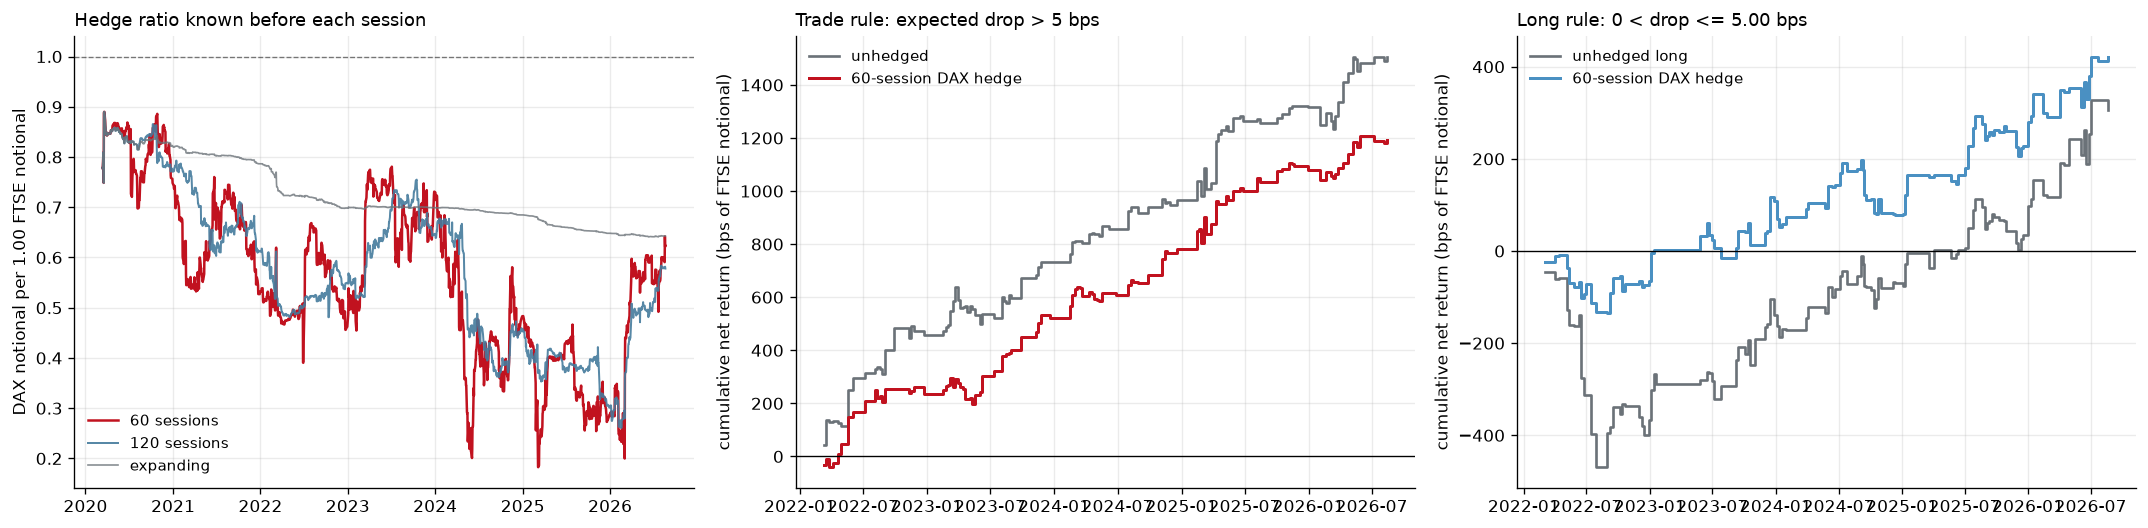

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18.0, 4.5))
ax = axes[0]
ax.plot(hedge.index, hedge["beta_60"], lw=1.5, color="#c1121f", label="60 sessions")
ax.plot(hedge.index, hedge["beta_120"], lw=1.2, color="#457b9d", alpha=0.9,
        label="120 sessions")
ax.plot(hedge.index, hedge["beta_expanding"], lw=1.0, color="#6b7278", alpha=0.8,
        label="expanding")
ax.axhline(1, color="k", lw=0.8, ls="--", alpha=0.5)
ax.set_ylabel("DAX notional per 1.00 FTSE notional")
ax.set_title("Hedge ratio known before each session", loc="left", fontsize=10.5)
ax.legend(frameon=False, fontsize=9)

ax = axes[1]
if len(event):
    u = event["unhedged_net_bps"].cumsum()
    h = event["hedged_beta_60_net_bps"].cumsum()
    ax.step(u.index, u, where="post", lw=1.6, color="#6b7278", label="unhedged")
    ax.step(h.index, h, where="post", lw=1.8, color="#c1121f",
            label="60-session DAX hedge")
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("cumulative net return (bps of FTSE notional)")
ax.set_title(f"Trade rule: expected drop > {EQUITY_THRESHOLD_BPS} bps",
             loc="left", fontsize=10.5)
ax.legend(frameon=False, fontsize=9)

ax = axes[2]
if len(long_event):
    u_long = long_event["long_unhedged_net_bps"].cumsum()
    h_long = long_event["long_hedged_beta_60_net_bps"].cumsum()
    ax.step(u_long.index, u_long, where="post", lw=1.6, color="#6b7278",
            label="unhedged long")
    ax.step(h_long.index, h_long, where="post", lw=1.8, color="#4a90c2",
            label="60-session DAX hedge")
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("cumulative net return (bps of FTSE notional)")
ax.set_title(f"Long rule: 0 < drop <= {small_trade_cut:.2f} bps",
             loc="left", fontsize=10.5)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## Findings

All numerical conclusions are printed by the executed cells above because they
change with `ANALYSIS_START`, `ANALYSIS_END`, and `BUCKET_CUTS`. Do not retain a
hard-coded headline after changing those controls.

### Historical-data limitation

The extended `Sheet1` history uses the **current constituent list, current index
weights and current prices** across the full selected period. It therefore has
survivorship bias and measurement error before the current snapshot: companies
that left the FTSE 100 are absent, companies that entered later may be treated as
members too early, and historical expected drops are not based on contemporaneous
weights or prices. Treat the extended regression as a robustness diagnostic, not
an accurately reconstructed historical index-dividend series.

The `none` group is also weekday-confounded because most UK ex-dividend dates are
Thursdays. The cleaner comparison remains large versus small ex-dividend dates.

## 12. Combined long-small and short-large gross P&L in USD

This final cell combines the two FTSE futures rules using the notebook's active
date range and `TRADE_EXIT_TIME`. It shows both the original unhedged strategy and
the same trades hedged with the lagged 60-session DAX notional ratio from section
11. Change `LONG_LOTS` and `SHORT_LOTS` to size the two legs independently. Both
figures and Sharpes are gross of spread, fees and slippage.

Unhedged combined gross P&L: $466,222
60-session DAX-hedged combined gross P&L: $441,849
Window: 08:00 -> 10:00 UK | GBP/USD: 1.3500
Long: 20 lots when 0 < drop <= 5.00 bps
Short: 20 lots when drop > 5.00 bps

Annualised gross event-return Sharpe (annualised using observed trades/year):
  unhedged graph: 1.71 (216 trades)
  DAX-hedged graph: 2.25 (214 trades)
  common-date comparison: unhedged 1.71 vs hedged 2.25 (214 trades each)

By strategy:
                  trades  total_usd  mean_usd
strategy                                     
long small           109   110430.0    1013.0
short large-drop     107   355792.0    3325.0

By calendar year:
      trades  total_usd
date                   
2022      41    25920.0
2023      46   111848.0
2024      50    79380.0
2025      48   113670.0
2026      31   135405.0


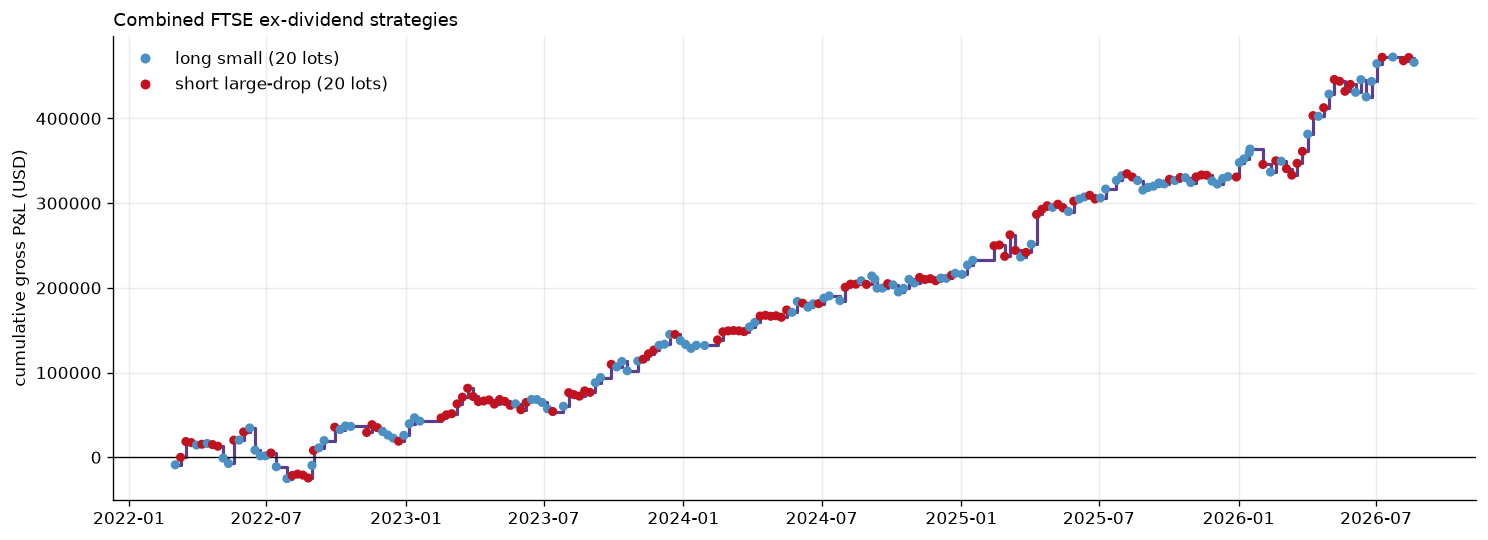

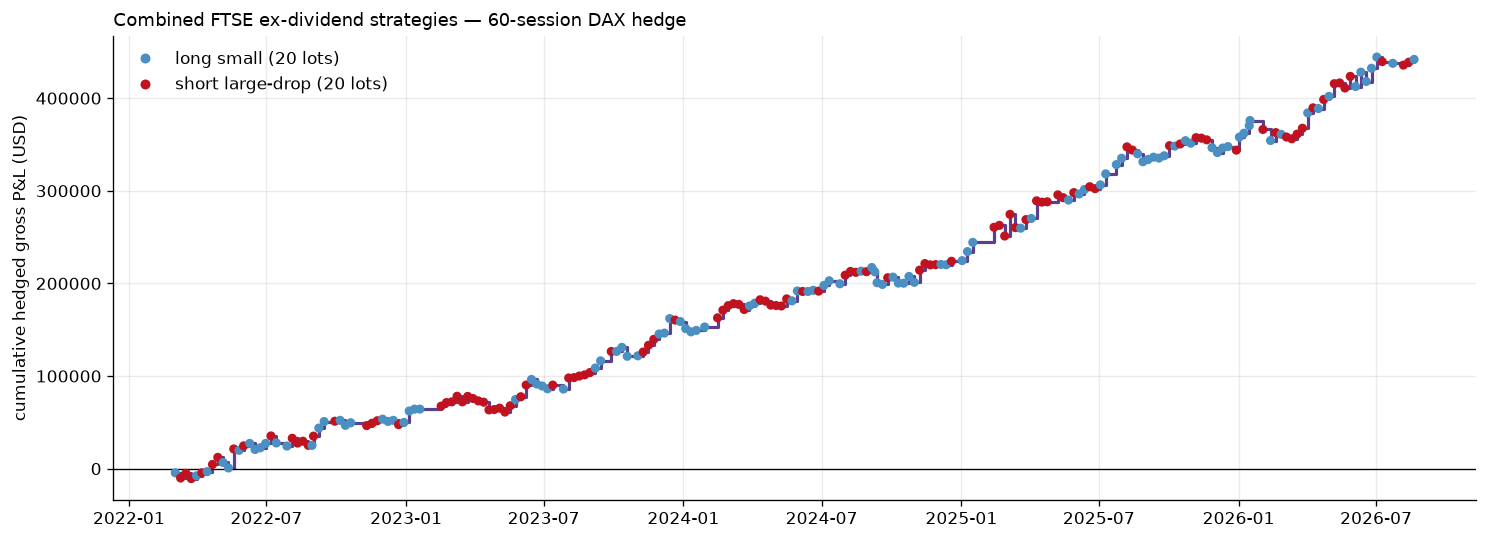

,graph,trades,gross_usd,annualised_gross_sharpe
0,unhedged,216,466222.0,1.71
1,60-session DAX hedge,214,441849.0,2.25
2,unhedged on hedge dates,214,465952.0,1.71


In [ ]:
# ============ COMBINED STRATEGY POSITION SIZES ============
LONG_LOTS = 20                 # long FTSE contracts on small ex-dividend dates
SHORT_LOTS = 20                # short FTSE contracts on large-drop dates
GBPUSD_FOR_PNL = GBPUSD        # USD per GBP; change if another conversion is wanted
# ==========================================================

for name, value in {"LONG_LOTS": LONG_LOTS, "SHORT_LOTS": SHORT_LOTS}.items():
    if not isinstance(value, (int, np.integer)) or value < 0:
        raise ValueError(f"{name} must be a non-negative whole number of contracts")
if not np.isfinite(GBPUSD_FOR_PNL) or GBPUSD_FOR_PNL <= 0:
    raise ValueError("GBPUSD_FOR_PNL must be a positive USD-per-GBP rate")

entry_px = mid[OPEN_M]
exit_px = mid[TRADE_EXIT_M]
move_points = exit_px - entry_px

long_mask = (bt["drop"] > 0) & (bt["drop"] <= small_trade_cut)
short_mask = bt["drop"] > EQUITY_THRESHOLD_BPS

parts = []
if LONG_LOTS:
    x = bt.loc[long_mask, ["drop"]].copy()
    x["strategy"] = "long small"
    x["lots"] = LONG_LOTS
    x["entry"] = entry_px.reindex(x.index)
    x["exit"] = exit_px.reindex(x.index)
    x["gross_points_per_contract"] = move_points.reindex(x.index)
    parts.append(x)
if SHORT_LOTS:
    x = bt.loc[short_mask, ["drop"]].copy()
    x["strategy"] = "short large-drop"
    x["lots"] = SHORT_LOTS
    x["entry"] = entry_px.reindex(x.index)
    x["exit"] = exit_px.reindex(x.index)
    x["gross_points_per_contract"] = -move_points.reindex(x.index)
    parts.append(x)

if not parts:
    raise ValueError("Set LONG_LOTS and/or SHORT_LOTS above zero")

combined_trades = pd.concat(parts).dropna(
    subset=["entry", "exit", "gross_points_per_contract"]
).sort_index()
if combined_trades.empty:
    raise ValueError("No executable trades in the selected analysis range")

combined_trades["gross_usd"] = (
    combined_trades["gross_points_per_contract"]
    * POINT_VALUE_GBP
    * combined_trades["lots"]
    * GBPUSD_FOR_PNL
)
combined_trades["gross_bps"] = (
    combined_trades["gross_points_per_contract"] / combined_trades["entry"] * 1e4
)
combined_trades["cumulative_gross_usd"] = combined_trades["gross_usd"].cumsum()

# Apply the same 60-session DAX hedge already defined and tested in section 11.
# The hedge output is in bps of FTSE notional; convert it back to USD so the
# hedged chart is directly comparable with the original 20-lot chart.
hedge_col = {
    "long small": "long_hedged_beta_60_gross_bps",
    "short large-drop": "hedged_beta_60_gross_bps",
}
hedged_combined = combined_trades.copy()
hedged_combined["hedged_gross_bps"] = [
    hedge.at[day, hedge_col[strategy]] if day in hedge.index else np.nan
    for day, strategy in zip(hedged_combined.index, hedged_combined["strategy"])
]
hedged_combined = hedged_combined.dropna(subset=["hedged_gross_bps"])
hedged_combined["hedged_gross_usd"] = (
    hedged_combined["hedged_gross_bps"] / 1e4
    * hedged_combined["entry"]
    * POINT_VALUE_GBP
    * hedged_combined["lots"]
    * GBPUSD_FOR_PNL
)
hedged_combined["cumulative_hedged_gross_usd"] = (
    hedged_combined["hedged_gross_usd"].cumsum()
)


def annualised_event_sharpe(s):
    'Gross event-return Sharpe, annualised by observed trades per year.'
    s = s.dropna()
    if len(s) < 2 or s.std(ddof=1) == 0:
        return np.nan
    trades_per_year = len(s) / years_covered(s.index)
    return s.mean() / s.std(ddof=1) * np.sqrt(trades_per_year)


unhedged_sharpe = annualised_event_sharpe(combined_trades["gross_bps"])
hedged_sharpe = annualised_event_sharpe(hedged_combined["hedged_gross_bps"])
common_unhedged = combined_trades.loc[hedged_combined.index, "gross_bps"]
common_unhedged_sharpe = annualised_event_sharpe(common_unhedged)

print(f"Unhedged combined gross P&L: ${combined_trades['gross_usd'].sum():,.0f}")
print(f"60-session DAX-hedged combined gross P&L: "
      f"${hedged_combined['hedged_gross_usd'].sum():,.0f}")
print(f"Window: 08:00 -> {TRADE_EXIT_TIME} UK | GBP/USD: {GBPUSD_FOR_PNL:.4f}")
print(f"Long: {LONG_LOTS} lots when 0 < drop <= {small_trade_cut:.2f} bps")
print(f"Short: {SHORT_LOTS} lots when drop > {EQUITY_THRESHOLD_BPS:.2f} bps")
print("\nAnnualised gross event-return Sharpe "
      "(annualised using observed trades/year):")
print(f"  unhedged graph: {unhedged_sharpe:.2f} "
      f"({len(combined_trades)} trades)")
print(f"  DAX-hedged graph: {hedged_sharpe:.2f} "
      f"({len(hedged_combined)} trades)")
print("  common-date comparison: "
      f"unhedged {common_unhedged_sharpe:.2f} vs hedged {hedged_sharpe:.2f} "
      f"({len(hedged_combined)} trades each)")
print("\nBy strategy:")
print(combined_trades.groupby("strategy")["gross_usd"]
      .agg(trades="count", total_usd="sum", mean_usd="mean")
      .round(0).to_string())
print("\nBy calendar year:")
print(combined_trades.groupby(combined_trades.index.year)["gross_usd"]
      .agg(trades="count", total_usd="sum")
      .round(0).to_string())

fig, ax = plt.subplots(figsize=(12.5, 4.6))
ax.step(combined_trades.index, combined_trades["cumulative_gross_usd"],
        where="post", color="#5b3f8c", lw=1.9)
colors = combined_trades["strategy"].map(
    {"long small": "#4a90c2", "short large-drop": "#c1121f"})
ax.scatter(combined_trades.index, combined_trades["cumulative_gross_usd"],
           c=colors, s=20, zorder=3)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("cumulative gross P&L (USD)")
ax.set_title("Combined FTSE ex-dividend strategies", loc="left", fontsize=11)
ax.ticklabel_format(axis="y", style="plain")
from matplotlib.lines import Line2D
ax.legend(handles=[
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#4a90c2",
           markeredgecolor="none", label=f"long small ({LONG_LOTS} lots)"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#c1121f",
           markeredgecolor="none", label=f"short large-drop ({SHORT_LOTS} lots)"),
], frameon=False)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12.5, 4.6))
ax.step(hedged_combined.index, hedged_combined["cumulative_hedged_gross_usd"],
        where="post", color="#5b3f8c", lw=1.9)
hedged_colors = hedged_combined["strategy"].map(
    {"long small": "#4a90c2", "short large-drop": "#c1121f"})
ax.scatter(hedged_combined.index,
           hedged_combined["cumulative_hedged_gross_usd"],
           c=hedged_colors, s=20, zorder=3)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("cumulative hedged gross P&L (USD)")
ax.set_title("Combined FTSE ex-dividend strategies — 60-session DAX hedge",
             loc="left", fontsize=11)
ax.ticklabel_format(axis="y", style="plain")
ax.legend(handles=[
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#4a90c2",
           markeredgecolor="none", label=f"long small ({LONG_LOTS} lots)"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#c1121f",
           markeredgecolor="none", label=f"short large-drop ({SHORT_LOTS} lots)"),
], frameon=False)
fig.tight_layout()
plt.show()

combined_summary = pd.DataFrame({
    "graph": ["unhedged", "60-session DAX hedge", "unhedged on hedge dates"],
    "trades": [len(combined_trades), len(hedged_combined), len(common_unhedged)],
    "gross_usd": [combined_trades["gross_usd"].sum(),
                  hedged_combined["hedged_gross_usd"].sum(),
                  combined_trades.loc[hedged_combined.index, "gross_usd"].sum()],
    "annualised_gross_sharpe": [unhedged_sharpe, hedged_sharpe,
                                common_unhedged_sharpe],
})
combined_summary.round({"gross_usd": 0, "annualised_gross_sharpe": 2})

ES control cache: 1473 dates; newly extracted 1
market model: 01:00-08:00 overnight; 08:00-10:00 trade; lookback 250 normal days
ES coverage in active range: 1126/1127 days
event dates with an ex-ante prediction: 216/216

Dividend-size relationship after alternative market adjustments:
                                          n  mean_move_bps  lambda  lambda_lo  lambda_hi       p  r_squared
measure                                                                                                    
raw FTSE                                216          -5.55   1.176      0.525      1.828  0.0005      0.055
minus predicted from ES overnight       216          -6.81   1.177      0.513      1.840  0.0006      0.053
minus predicted from ES + FT overnight  216          -7.18   1.216      0.552      1.880  0.0004      0.057
same-window ES beta hedge               216          -4.17   1.089      0.608      1.570  0.0000      0.084
normal-day variance removed by ES-overnight forecast: -1.7% (n=91

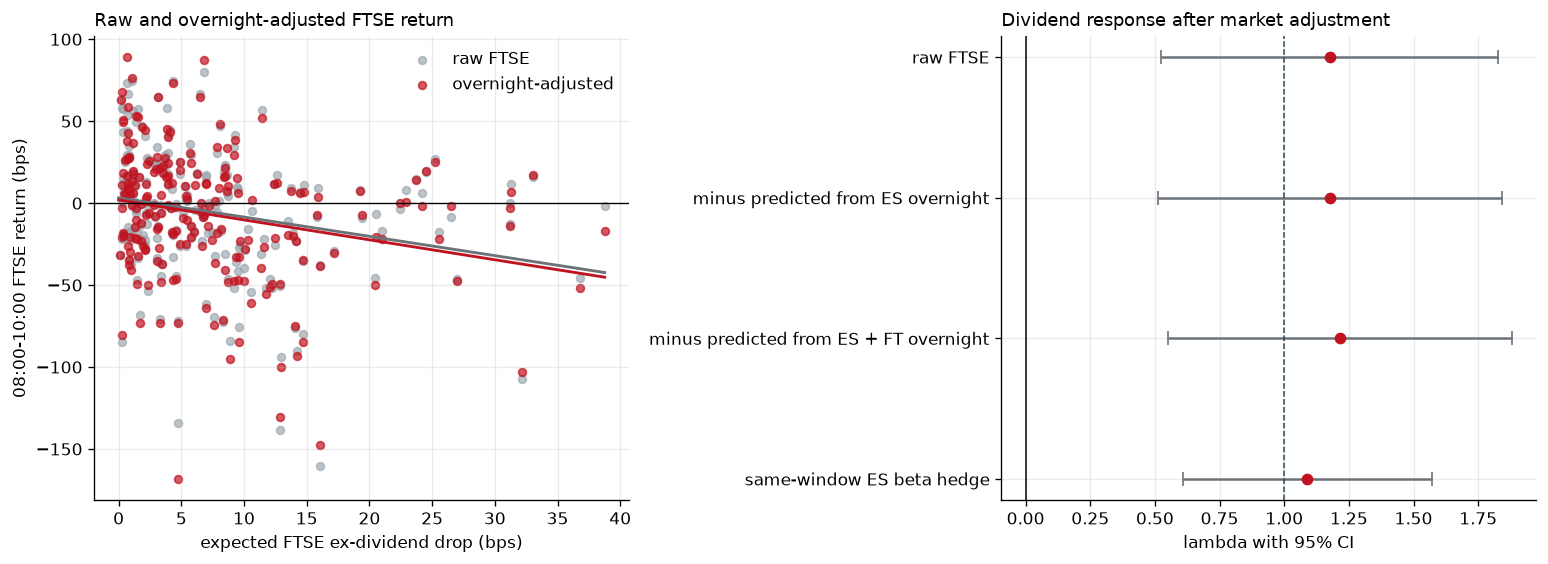


Interpretation:
- The two overnight models are genuine 08:00 predictions.
- The same-window ES result is a tradable beta hedge, not a pre-trade forecast.
- Stability of lambda across rows is stronger evidence than any one specification.


In [ ]:
# 11. Market-adjusted FTSE move: overnight S&P model and tradable hedge
#
# This cell reports three versions of the 08:00 -> selected-exit FTSE return:
#   1) raw;
#   2) ex-ante abnormal return, subtracting a rolling prediction made at 08:00;
#   3) a same-window ES beta hedge, which is tradable but known only ex post.
# Models are fitted only on earlier non-ex-dividend observations.

# ============ MARKET-ADJUSTMENT PARAMETERS ============
ES_TICK_DIR = Path(r"D:\tick_data\100_ms\ES")
OVERNIGHT_START_TIME = "01:00"       # aligned with the FT futures session
MARKET_MODEL_LOOKBACK = 250           # preceding normal observations
MARKET_MODEL_MIN_TRAIN = 60
MARKET_MODEL_HISTORY_DAYS = 500        # history loaded before the active analysis
MARKET_CACHE = Path(
    f"ftse_es_controls_{OVERNIGHT_START_TIME.replace(':', '')}_"
    f"{TRADE_EXIT_TIME.replace(':', '')}.parquet"
)
# ======================================================


def _es_front_month_file(day_dir):
    """Largest ES contract file for the date, matching the notebook convention."""
    best, best_size = None, 0
    if not day_dir.exists():
        return None
    for path in day_dir.glob("FUT_ES*.csv"):
        size = path.stat().st_size
        if size > best_size:
            best, best_size = path, size
    return best if best_size > 50_000 else None


def _line_epoch(line):
    """Read UnixTs from one encoded CSV row; return NaN for headers/bad rows."""
    try:
        return float(line.split(b",", 2)[1])
    except (IndexError, ValueError):
        return np.nan


def _offset_near_epoch(path, target):
    """Binary-search a sorted tick CSV by UnixTs without loading the whole file."""
    size = path.stat().st_size
    lo, hi = 0, size
    with path.open("rb") as fh:
        for _ in range(32):
            if hi - lo < 4096:
                break
            mid_ = (lo + hi) // 2
            fh.seek(mid_)
            if mid_:
                fh.readline()  # discard partial row
            pos = fh.tell()
            line = fh.readline()
            ts = _line_epoch(line)
            if not np.isfinite(ts):
                lo = min(fh.tell(), size)
            elif ts < target:
                lo = pos
            else:
                hi = mid_
    return max(lo, 0)


def _mid_near(path, target, max_age_seconds=300):
    """Nearest usable quote around target, preferring the last quote before it."""
    near = _offset_near_epoch(path, target)
    start = max(0, near - 2_000_000)
    last_mid, last_ts = np.nan, np.nan
    first_after_mid, first_after_ts = np.nan, np.nan
    with path.open("rb") as fh:
        fh.seek(start)
        if start:
            fh.readline()
        while True:
            line = fh.readline()
            if not line:
                break
            parts = line.rstrip(b"\r\n").split(b",")
            if len(parts) < 6 or parts[0].startswith(b"#"):
                continue
            try:
                ts = float(parts[1])
            except ValueError:
                continue
            if ts > target + max_age_seconds:
                break
            if parts[2] == b"Q" and parts[4] and parts[5]:
                try:
                    value = (float(parts[4]) + float(parts[5])) / 2.0
                    if ts <= target:
                        last_mid, last_ts = value, ts
                    elif not np.isfinite(first_after_ts):
                        first_after_mid, first_after_ts = value, ts
                except ValueError:
                    pass
    if np.isfinite(last_ts) and target - last_ts <= max_age_seconds:
        return last_mid
    if np.isfinite(first_after_ts) and first_after_ts - target <= max_age_seconds:
        return first_after_mid
    return np.nan


def _clock(text):
    hour, minute = (int(x) for x in text.split(":"))
    return dt.time(hour, minute)


def build_es_controls(wanted, force=False):
    """ES levels at overnight start, FTSE open and selected trade exit."""
    cached = None
    if MARKET_CACHE.exists() and not force:
        cached = pd.read_parquet(MARKET_CACHE)
        cached.index = pd.to_datetime(cached.index)
    level_cols = ["es_overnight_start", "es_open", "es_exit"]
    have = (set() if cached is None else
            set(cached.dropna(subset=level_cols).index))
    rows = []
    wanted = pd.DatetimeIndex(wanted)
    for number, day in enumerate(wanted, 1):
        if day in have:
            continue
        day_dir = ES_TICK_DIR / day.strftime("%Y%m%d")
        path = _es_front_month_file(day_dir)
        if path is None:
            continue
        targets = {
            "es_overnight_start": uk_epoch(day, _clock(OVERNIGHT_START_TIME)),
            "es_open": uk_epoch(day, dt.time(8, 0)),
            "es_exit": uk_epoch(day, TRADE_EXIT_CLOCK),
        }
        row = {"date": day, "es_contract": path.stem.replace("FUT_", "")}
        row.update({name: _mid_near(path, epoch) for name, epoch in targets.items()})
        rows.append(row)
        if number % 250 == 0:
            print(f"ES controls: checked {number}/{len(wanted)} dates")
    fresh = pd.DataFrame(rows).set_index("date") if rows else pd.DataFrame()
    if cached is None:
        out = fresh
    elif fresh.empty:
        out = cached
    else:
        out = pd.concat([cached, fresh])
        out = out[~out.index.duplicated(keep="last")]
        out = out.sort_index()
    out.to_parquet(MARKET_CACHE)
    print(f"ES control cache: {len(out)} dates; newly extracted {len(fresh)}")
    return out.reindex(wanted)


# The active notebook may start recently.  Pull a bounded prior history from the
# existing FT panel cache so January event dates still get out-of-sample forecasts.
if PANEL_CACHE.exists():
    market_panel = pd.read_parquet(PANEL_CACHE)
    market_panel["date"] = pd.to_datetime(market_panel["date"])
    market_mid_all = market_panel.pivot_table(index="date", columns="m", values="mid")
else:
    market_mid_all = mid.copy()
history_start = analysis_start - pd.Timedelta(days=MARKET_MODEL_HISTORY_DAYS)
market_mid = market_mid_all[market_mid_all.index >= history_start].copy()

es_controls = build_es_controls(market_mid.index)
market = pd.DataFrame(index=market_mid.index)
market["expected_drop_bps"] = exdiv["drop_bps"].reindex(market.index).fillna(0.0)
market["weekday"] = market.index.day_name()
market["raw_trade_bps"] = (
    (market_mid[TRADE_EXIT_M] - market_mid[OPEN_M]) / market_mid[OPEN_M] * 1e4
)
# The within-session FT overnight move avoids a cross-contract roll between days.
market["ft_overnight_bps"] = (
    (market_mid[OPEN_M] - market_mid[uk_to_m(OVERNIGHT_START_TIME)])
    / market_mid[uk_to_m(OVERNIGHT_START_TIME)] * 1e4
)
market = market.join(es_controls)
market["es_overnight_bps"] = (
    (market["es_open"] - market["es_overnight_start"])
    / market["es_overnight_start"] * 1e4
)
market["es_trade_bps"] = (
    (market["es_exit"] - market["es_open"]) / market["es_open"] * 1e4
)
# Before the workbook's labelled analysis period, exclude Thursdays from model
# training because historical ex-dividend labels may be incomplete.  Inside the
# active period, use every day explicitly labelled with zero expected drop.
market["training_normal"] = np.where(
    market.index < analysis_start,
    ~market["weekday"].eq("Thursday"),
    market["expected_drop_bps"].eq(0.0),
)


def rolling_normal_return(frame, features):
    """Prior-data-only OLS prediction trained on non-ex-dividend observations."""
    prediction = pd.Series(np.nan, index=frame.index, dtype=float)
    alpha = pd.Series(np.nan, index=frame.index, dtype=float)
    betas = pd.DataFrame(np.nan, index=frame.index, columns=features)
    required = ["raw_trade_bps", "training_normal", *features]
    for date in frame.index:
        x_now = frame.loc[date, features]
        if x_now.isna().any():
            continue
        history = frame.loc[frame.index < date, required].dropna()
        history = history[history["training_normal"]].tail(
            MARKET_MODEL_LOOKBACK
        )
        if len(history) < MARKET_MODEL_MIN_TRAIN:
            continue
        X = np.column_stack([np.ones(len(history)), history[features].to_numpy()])
        coef = np.linalg.lstsq(X, history["raw_trade_bps"].to_numpy(), rcond=None)[0]
        prediction.loc[date] = coef[0] + np.dot(x_now.to_numpy(), coef[1:])
        alpha.loc[date] = coef[0]
        betas.loc[date] = coef[1:]
    return prediction, alpha, betas


# Ex-ante model 1: S&P overnight only.  This cannot absorb a FTSE-specific
# dividend anticipation that may already appear in the FT overnight return.
market["pred_es_overnight"], _, beta_es_overnight = rolling_normal_return(
    market, ["es_overnight_bps"]
)
market["abnormal_es_overnight"] = (
    market["raw_trade_bps"] - market["pred_es_overnight"]
)

# Ex-ante model 2: S&P plus the FTSE's own 01:00-08:00 move.  Treat this as a
# robustness test because it may control away dividend anticipation.
market["pred_es_ft_overnight"], _, beta_es_ft_overnight = rolling_normal_return(
    market, ["es_overnight_bps", "ft_overnight_bps"]
)
market["abnormal_es_ft_overnight"] = (
    market["raw_trade_bps"] - market["pred_es_ft_overnight"]
)

# Tradable contemporaneous hedge: beta-adjust the FTSE trade by the ES move over
# exactly the same interval.  This is not an 08:00 forecast; it is realised hedge P&L.
market["pred_es_same_window"], _, beta_es_trade = rolling_normal_return(
    market, ["es_trade_bps"]
)
market["abnormal_es_same_window"] = (
    market["raw_trade_bps"] - market["pred_es_same_window"]
)


def dividend_slope(column, label):
    sample = market.loc[market["expected_drop_bps"] > 0,
                        ["expected_drop_bps", column]].dropna()
    result = stats.linregress(sample["expected_drop_bps"], sample[column])
    return {
        "measure": label,
        "n": len(sample),
        "mean_move_bps": sample[column].mean(),
        "lambda": -result.slope,
        "lambda_lo": -(result.slope + 1.96 * result.stderr),
        "lambda_hi": -(result.slope - 1.96 * result.stderr),
        "p": result.pvalue,
        "r_squared": result.rvalue ** 2,
    }


comparison = pd.DataFrame([
    dividend_slope("raw_trade_bps", "raw FTSE"),
    dividend_slope("abnormal_es_overnight", "minus predicted from ES overnight"),
    dividend_slope("abnormal_es_ft_overnight", "minus predicted from ES + FT overnight"),
    dividend_slope("abnormal_es_same_window", "same-window ES beta hedge"),
]).set_index("measure")

active_market = market[market.index >= analysis_start]
event_rows = active_market[active_market["expected_drop_bps"] > 0]
print(f"market model: {OVERNIGHT_START_TIME}-08:00 overnight; "
      f"08:00-{TRADE_EXIT_TIME} trade; lookback {MARKET_MODEL_LOOKBACK} normal days")
print(f"ES coverage in active range: "
      f"{active_market['es_overnight_bps'].notna().sum()}/{len(active_market)} days")
print(f"event dates with an ex-ante prediction: "
      f"{event_rows['abnormal_es_ft_overnight'].notna().sum()}/"
      f"{len(event_rows)}")
print("\nDividend-size relationship after alternative market adjustments:")
print(comparison.round({"mean_move_bps": 2, "lambda": 3, "lambda_lo": 3,
                        "lambda_hi": 3, "p": 4, "r_squared": 3}).to_string())

normal = active_market[active_market["expected_drop_bps"].eq(0.0)]
for column, label in [
        ("abnormal_es_overnight", "ES-overnight forecast"),
        ("abnormal_es_ft_overnight", "ES + FT overnight forecast"),
        ("abnormal_es_same_window", "same-window ES hedge")]:
    valid = normal[["raw_trade_bps", column]].dropna()
    reduction = 1 - valid[column].var(ddof=1) / valid["raw_trade_bps"].var(ddof=1)
    print(f"normal-day variance removed by {label}: {reduction * 100:+.1f}% "
          f"(n={len(valid)})")

fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.8))
ax = axes[0]
plot_sample = event_rows[["expected_drop_bps", "raw_trade_bps",
                          "abnormal_es_ft_overnight"]].dropna()
ax.scatter(plot_sample["expected_drop_bps"], plot_sample["raw_trade_bps"],
           s=22, color="#9aa5ad", alpha=0.65, label="raw FTSE")
ax.scatter(plot_sample["expected_drop_bps"],
           plot_sample["abnormal_es_ft_overnight"],
           s=22, color="#c1121f", alpha=0.70, label="overnight-adjusted")
for column, color in [("raw_trade_bps", "#6b7278"),
                      ("abnormal_es_ft_overnight", "#c1121f")]:
    fit = stats.linregress(plot_sample["expected_drop_bps"], plot_sample[column])
    xx = np.array([0.0, plot_sample["expected_drop_bps"].max()])
    ax.plot(xx, fit.intercept + fit.slope * xx, color=color, lw=1.7)
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("expected FTSE ex-dividend drop (bps)")
ax.set_ylabel(f"08:00-{TRADE_EXIT_TIME} FTSE return (bps)")
ax.set_title("Raw and overnight-adjusted FTSE return", loc="left", fontsize=10.5)
ax.legend(frameon=False)

ax = axes[1]
plot_cmp = comparison.reset_index()
y = np.arange(len(plot_cmp))
err = np.vstack([plot_cmp["lambda"] - plot_cmp["lambda_lo"],
                 plot_cmp["lambda_hi"] - plot_cmp["lambda"]])
ax.errorbar(plot_cmp["lambda"], y, xerr=err, fmt="o", capsize=4,
            color="#c1121f", ecolor="#6b7278")
ax.axvline(0, color="k", lw=0.9)
ax.axvline(1, color="#264653", lw=0.9, ls="--")
ax.set_yticks(y)
ax.set_yticklabels(plot_cmp["measure"])
ax.invert_yaxis()
ax.set_xlabel("lambda with 95% CI")
ax.set_title("Dividend response after market adjustment", loc="left", fontsize=10.5)
fig.tight_layout()
plt.show()

print("\nInterpretation:")
print("- The two overnight models are genuine 08:00 predictions.")
print("- The same-window ES result is a tradable beta hedge, not a pre-trade forecast.")
print("- Stability of lambda across rows is stronger evidence than any one specification.")


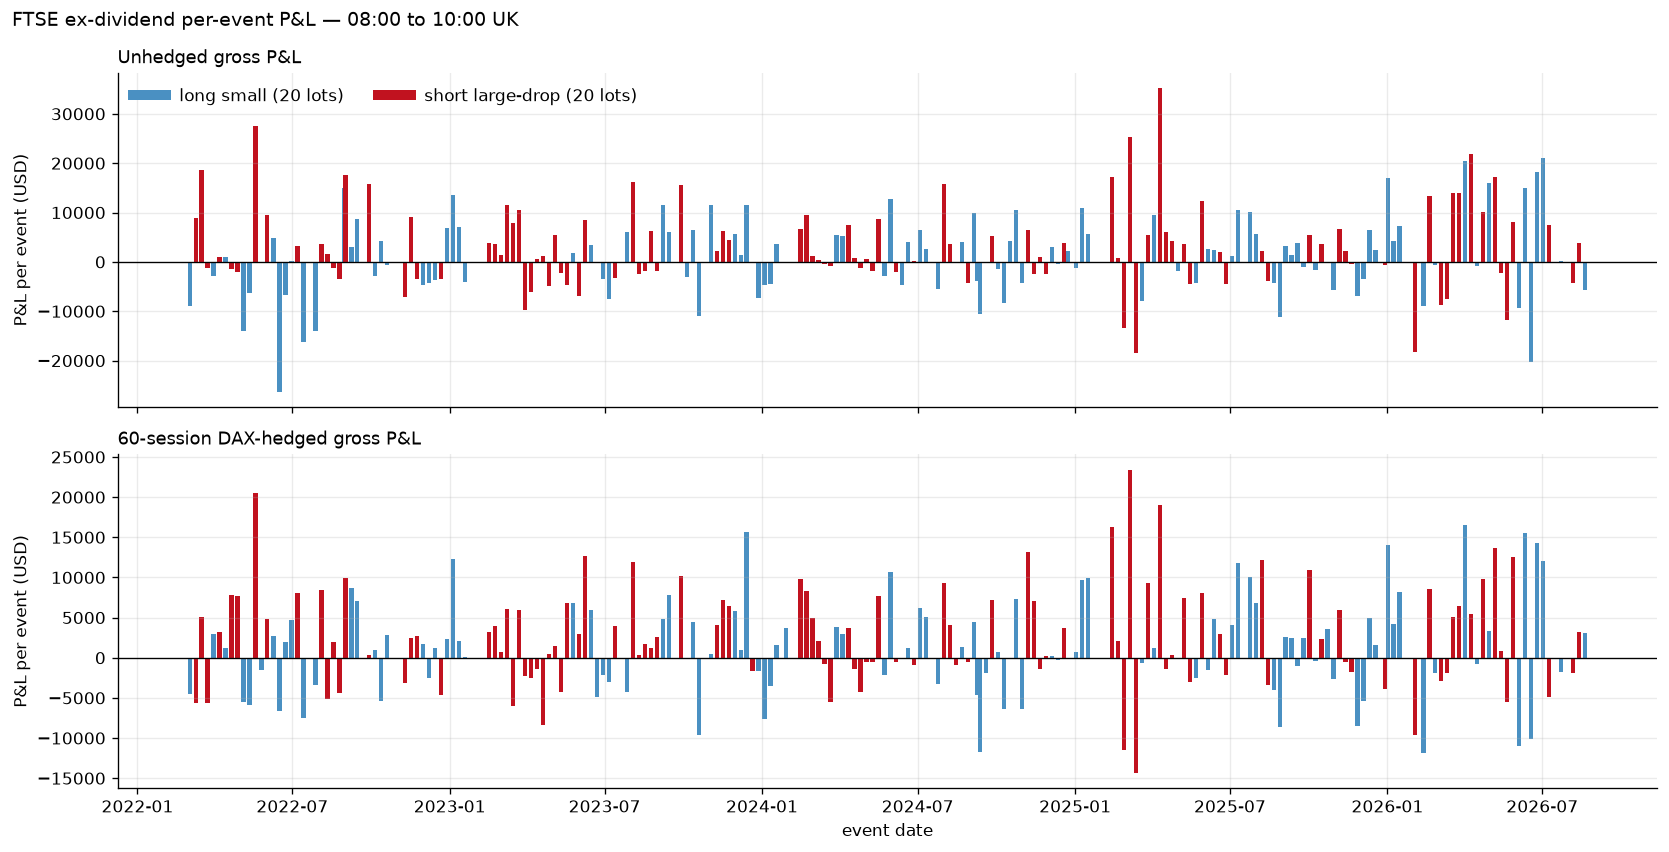

In [ ]:
# Per-event P&L through time (non-cumulative). Colours retain the notebook's
# convention: blue = long-small; red = short-large-drop.
strategy_colors = {
    "long small": "#4a90c2",
    "short large-drop": "#c1121f",
}

fig, axes = plt.subplots(2, 1, figsize=(14.0, 7.2), sharex=True)
panels = [
    (axes[0], combined_trades, "gross_usd", "Unhedged gross P&L"),
    (axes[1], hedged_combined, "hedged_gross_usd",
     "60-session DAX-hedged gross P&L"),
]
for ax, frame, pnl_col, title in panels:
    event_pnl = frame.sort_index()
    colors = event_pnl["strategy"].map(strategy_colors)
    ax.bar(event_pnl.index, event_pnl[pnl_col], width=5.0,
           color=colors, edgecolor="none")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_ylabel("P&L per event (USD)")
    ax.set_title(title, loc="left", fontsize=10.5)
    ax.ticklabel_format(axis="y", style="plain")

axes[1].set_xlabel("event date")
axes[0].legend(handles=[
    Line2D([0], [0], color="#4a90c2", lw=6,
           label=f"long small ({LONG_LOTS} lots)"),
    Line2D([0], [0], color="#c1121f", lw=6,
           label=f"short large-drop ({SHORT_LOTS} lots)"),
], frameon=False, ncol=2)
fig.suptitle(
    f"FTSE ex-dividend per-event P&L — 08:00 to {TRADE_EXIT_TIME} UK",
    x=0.01, ha="left", fontsize=11.5,
)
fig.tight_layout()
plt.show()


In [ ]:
# Daily export of unhedged and DAX-hedged returns for outside analysis.
# One row per common FTSE/DAX session in the active range, ex-dividend or not,
# so the rules can be re-cut freely.  All returns are bps of FTSE notional,
# 08:00 -> TRADE_EXIT_TIME UK (DAX leg 09:00 Berlin -> same elapsed time).
# Sign conventions match section 11:
#   short_*  = short FTSE (+ long beta DAX when hedged)
#   long_*   = long FTSE  (+ short beta DAX when hedged)
#   *_net    = gross minus half-spread at entry and exit on each leg
EXPORT_CSV = Path(
    f"ftse_exdiv_daily_returns_0800_{TRADE_EXIT_TIME.replace(':', '')}.csv")

in_range = (hedge.index >= analysis_start) & (hedge.index <= analysis_end)
export = pd.DataFrame(index=hedge.index[in_range])
export.index.name = "date"
export["weekday"] = export.index.day_name()
export["expected_drop_bps"] = hedge.loc[export.index, "drop"]
export["group"] = hedge.loc[export.index, "group"]
export["rule"] = np.select(
    [export["expected_drop_bps"] > EQUITY_THRESHOLD_BPS,
     (export["expected_drop_bps"] > 0)
     & (export["expected_drop_bps"] <= small_trade_cut)],
    ["short large-drop", "long small"], default="")

export["ftse_entry"] = hedge_ft_mid.loc[export.index, OPEN_M]
export["ftse_exit"] = hedge_ft_mid.loc[export.index, TRADE_EXIT_M]
export["dax_entry"] = dax_mid.loc[export.index, DAX_OPEN_M]
export["dax_exit"] = dax_mid.loc[export.index, DAX_EXIT_M]
export = export.join(hedge[[
    "ftse_bps", "dax_bps", "eurgbp_entry", "eurgbp_exit",
    "beta_60", "beta_120", "beta_expanding", "fdax_per_ftse_beta_60",
    "ftse_cost_bps", "dax_cost_per_dax_notional_bps",
]])

for side, prefix in [("short", ""), ("long", "long_")]:
    for kind in ["gross", "net"]:
        export[f"{side}_unhedged_{kind}_bps"] = hedge[f"{prefix}unhedged_{kind}_bps"]
        for b in ["beta_60", "beta_120", "beta_expanding"]:
            export[f"{side}_hedged_{b}_{kind}_bps"] =                 hedge[f"{prefix}hedged_{b}_{kind}_bps"]

# P&L of whichever rule fires that day (blank on no-trade days), 60-session hedge.
for kind in ["gross", "net"]:
    for leg, col in [("unhedged", "unhedged"), ("hedged_beta_60", "hedged_beta_60")]:
        export[f"rule_{leg}_{kind}_bps"] = np.select(
            [export["rule"].eq("short large-drop"), export["rule"].eq("long small")],
            [export[f"short_{col}_{kind}_bps"], export[f"long_{col}_{kind}_bps"]],
            default=np.nan)

export.to_csv(EXPORT_CSV, float_format="%.6f")
print(f"wrote {EXPORT_CSV.resolve()}")
print(f"{len(export)} sessions {export.index.min().date()} .. "
      f"{export.index.max().date()}; "
      f"{(export['expected_drop_bps'] > 0).sum()} ex-dividend, "
      f"{export['rule'].ne('').sum()} rule trades, "
      f"beta_60 available on {export['beta_60'].notna().sum()}")


wrote C:\repo\ex_div_dates_research\FTSE\ftse_exdiv_daily_returns_0800_1000.csv
1120 sessions 2022-03-03 .. 2026-08-20; 214 ex-dividend, 214 rule trades, beta_60 available on 1120
